# Conditional squeezing and conditional rotation from a π-pulse train

**What this notebook shows.** A continuous sideband plus a train of 30 ns qubit π pulses, with each pulse's qubit phase and each cell's sideband phase chosen by an optimiser, approximates both conditional gates, evaluated on all 18 input basis states. Ideal coherent model: two-level qubit, no loss, no static χ.

**Results at today's 600 ns sideband swap:**

| gate | time | π pulses | gap between pulses | gate fidelity (18 inputs) |
|---|---|---|---|---|
| 8 dB conditional squeezing | **7.61 µs** | 160 | 17.5 ns | **99.93 %** |
| 8 dB conditional squeezing | 6.73 µs | 128 | 22.5 ns | 99.69 % |
| conditional rotation (π relative) | **8.81 µs** | 160 | 25 ns | **99.97 %** |
| conditional rotation (π relative) | 7.61 µs | 160 | 17.5 ns | 99.60 % |

With a 2× stronger sideband (300 ns swap) both gates take 4.81 µs at 99.96 % and 99.98 %. Every gate was replayed through the SDK word and documented linear RFDC chain (16-bit I/Q words plus the converter's interpolation filter) and agrees with the model to within $3.2\times10^{-5}$.

**What made them shorter** than the earlier 12.8 µs gates in this folder: fewer π pulses with sideband-only gaps between them, at the same total time (Section 6), and running the optimiser long enough to converge (Section 5).

**How the squeezer works** (Section 3): conditional-force commutators motivate the seeds. The optimiser fits the full finite-pulse unitary, not a loop area. Section 3 now checks a finite-drive toggling-frame diagnostic from the actual played waveform; a truncated Magnus expansion is not an exact gate explanation.

Sections: 1 targets · 2 hardware and model · 3 why it works · 4 fidelity · 5 optimiser · 6 how short · 7 structure · 8 the gates, each with its full pulse diagram, I/Q, errors and Wigner functions · 9 conclusions. Files: `cd_trains.py` (model), `optimise_trains.py` (all optimisations), `hardware_check.py` (board waveform), `cd_plots.py` (figures); results in `runs/`.

**Scope:** all scores in this notebook are coherent process fidelities in the stated effective model. Numerical accuracy and physical device-model accuracy are separate checks.

## 1. What we want

Two gates on qubit ⊗ cavity, conditioned on the qubit ($\sigma_z|g\rangle = +|g\rangle$):

$$S_z(r) = |g\rangle\langle g|\otimes S(r) + |e\rangle\langle e|\otimes S(-r),\qquad S(r)=e^{\frac r2(a^2-a^{\dagger 2})},\qquad r = \tfrac{8\ln 10}{20} = 0.921 \;(8\text{ dB})$$

$$R_z = e^{-i\frac{\pi}{2}\sigma_z n} = |g\rangle\langle g|\otimes e^{-i\frac\pi2 n} + |e\rangle\langle e|\otimes e^{+i\frac\pi2 n}\qquad(\text{the two branches rotate by }\mp 90°,\ \pi\text{ relative})$$

**Squeezing:** if the qubit is in g the cavity is squeezed along one quadrature, if it is in e along the orthogonal one. **Rotation:** the cavity's phase space turns by −90° for g and +90° for e. Both act on any qubit state, including superpositions. The picture below shows the ideal targets on (|g⟩+|e⟩)/√2 ⊗ cavity: vacuum for the squeezer, a coherent state α = 1.5 for the rotation.

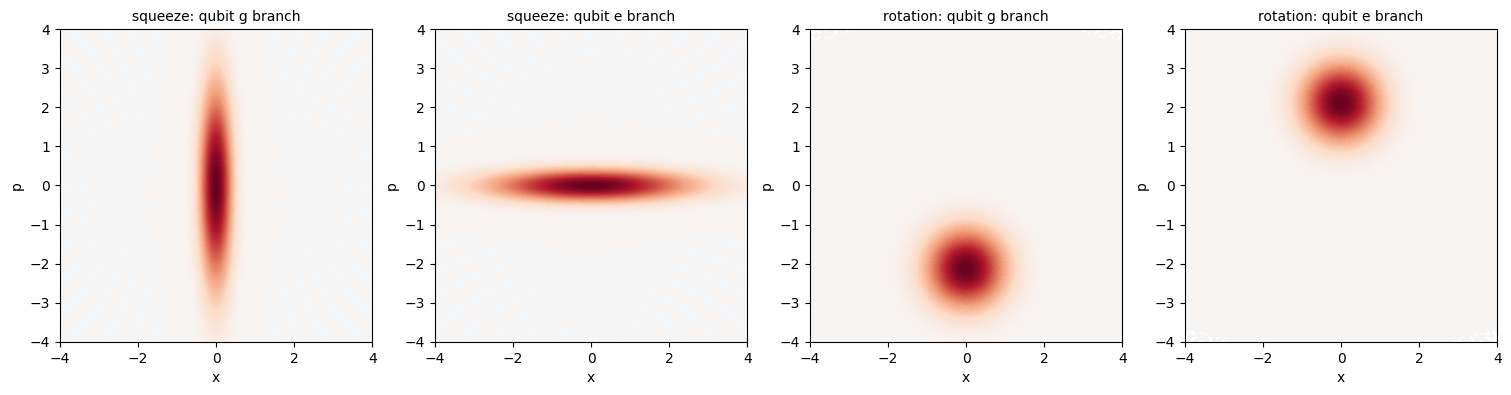

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS

import json, os
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cd_trains as cd
import cd_plots as cp

RUNS = "runs"
STRENGTH = {"squeeze": cd.R_8DB, "rotation": np.pi / 2}
LEVELS = {"squeeze": 96, "rotation": 48}            # enough photon levels (checked below)
final = json.load(open(f"{RUNS}/final.json"))       # the recommended gates (made by: python optimise_trains.py final)
runs = {name: json.load(open(f"{RUNS}/{name}.json")) for name in ("sweep", "round2", "round3")}


def train_of(result, levels=None):
    job = result["job"]
    return cd.Train(job["gate"], STRENGTH[job["gate"]], job["swap"], job["cells"], job["gap"], levels or max(LEVELS[job["gate"]], result["hardware_check"]["levels"]))


def controls_of(result):
    return np.r_[result["qubit_phases"], result["pump_phases"]]


# ideal targets on (|g> + |e>)/sqrt2 x vacuum (squeeze) or x coherent alpha = 1.5 (rotation)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), constrained_layout=True)
grid = np.linspace(-4, 4, 161)
for gate, state, pair in (("squeeze", None, axes[:2]), ("rotation", 1.5, axes[2:])):
    tr = cd.Train(gate, STRENGTH[gate], 0.6, 2, 0.0, 48)
    psi = np.zeros(48, complex)
    if state is None:
        psi[0] = 1
    else:
        psi = cp.coherent(48, state)
    for ax, ket, branch in zip(pair, cp.ideal_branches(tr, psi), ("g", "e")):
        W = cp.qt.wigner(cp.qt.Qobj(ket[:, None]), grid, grid)
        ax.contourf(grid, grid, W, 60, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
        ax.set_aspect("equal"); ax.set_title(f"{gate}: qubit {branch} branch", fontsize=10)
        ax.set_xlabel("x"); ax.set_ylabel("p")
plt.show()

playbacks=pd.read_csv(f"{RUNS}/audit/search_playback.csv")
assert len(playbacks)==1241
played_lookup={(r['group'],int(r['index'])):r.fidelity for _,r in playbacks.iterrows()}


## 2. What we can play

Two drives, both written to the board sample by sample (800 MS/s, 1.25 ns per sample):

* a **resonant sideband** ("pump") that swaps a qubit excitation into the cavity: $H_{\rm sb} = g\,(e^{i\psi}\sigma_+ a + {\rm h.c.})$. Its strength is set by the full-swap time: $g = \pi/(2t_{\rm swap})$. **600 ns is today's calibrated swap**; 300 ns means a 2× stronger sideband. It stays on for the whole gate (5 ns ramps at the start and end only).
* **30 ns Hann π pulses** on the qubit, $\Omega(t)(e^{i\phi}\sigma_+ + {\rm h.c.})$, 24 samples each.

No static dispersive shift is included.

A gate is a **train of N cells**. Cell $j$ = half gap, one π pulse with qubit phase $\phi_j$, half gap; the sideband has phase $\psi_j$ during the whole cell. **The only numbers we choose are the 2N phases** (and N, the gap, the swap). Gate time $T = N(30\text{ ns} + \text{gap}) + 10$ ns.

The simulation integrates exactly this, sample by sample (two-level qubit, no loss, no static χ). Since a cell's phases only rotate the frame, every cell is the same matrix $U_0$ conjugated by a diagonal phase: $C_j = D_j U_0 D_j^\dagger$, $D_j = e^{i(\phi_j k - \psi_j n)}$ with $k = n + |e\rangle\langle e| - \tfrac12$. One $U_0$ per (swap, gap) is computed once (`cd_trains.py`).

Example: the first 4 π pulses of a final gate:

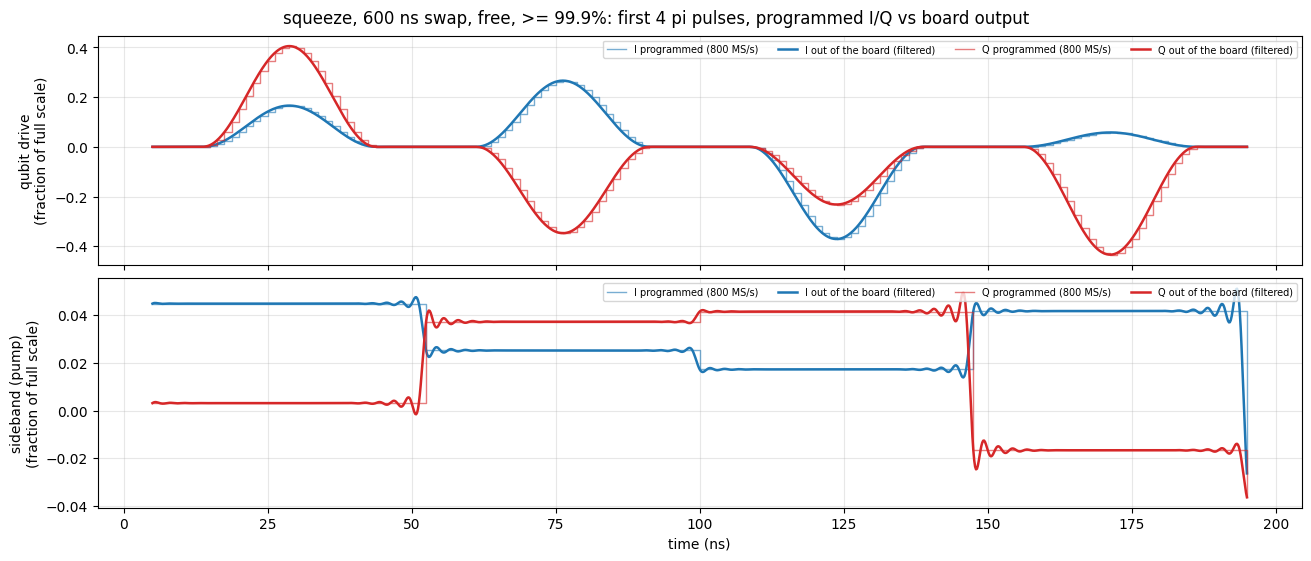

In [2]:
example = final[0]
tr = train_of(example)
x = controls_of(example)
cp.iq_plot(tr, x, start_pulse=0, n_pulses=4, title=f"{example['job']['label']}: first 4 pi pulses, programmed I/Q vs board output")

**Reading the I/Q plot.** Steps are SDK-loaded int16 samples; lines are the documented linear 8× RFDC response, visually shifted by its known 22.65625 ns group delay. Propagation uses the unshifted full arrays, including the 44.21875 ns startup/tail window beyond command time. The converter's internal rounding and analog transfer function are unmeasured here.

**Phase convention matters:** the model coefficient multiplies $\sigma_+$, while the supplied programmed CD model's qubit I/Q multiplies $\sigma_-$. Thus qubit DAC phase is **minus** the model phase; pump DAC phase is the model phase. Pulse diagrams, CSVs and integer exports now use the correct DAC phases. Carrier NCOs remain fixed. Phase changes are samples inside one `use_stretch=False` buffer per channel, rather than rapid sequencer phase commands. All 16 recommended gates have been compiled offline as two arbitrary-waveform commands with one common trigger each.

## 3. What mechanism the optimizer can use

The seed argument starts from conditional forces. In the frame following the actual finite qubit drive $Q(t)$,

$$H_I(t)/\hbar=\sum_{\mu=x,y,z}\sigma_\mu\big[c_\mu(t)a+c_\mu^*(t)a^\dagger\big],\qquad
c_\mu(t)=s(t)\,\operatorname{Tr}\!\left[\sigma_\mu Q^\dagger(t)\sigma_+Q(t)\right]/2.$$

The qubit drive and sideband here are the SDK-quantized, RFDC-interpolated arrays. We integrate the qubit-only motion exactly per sample and evaluate the sideband in its midpoint frame. The full gate simulation retains both simultaneous controls; this diagnostic does not replace it.

Write $U_I=\exp[-i(G_1+G_2+\cdots)]$. With $C_\mu(t)=\int_0^t c_\mu(u)du$, the second-order Hermitian generator, omitting a global scalar, is

$$G_2=\sum_\kappa\sigma_\kappa\left[K_\kappa a^2+K_\kappa^*a^{\dagger2}+R_\kappa(2n+1)\right],$$

$$K_\kappa=\sum_{\mu\nu}\epsilon_{\mu\nu\kappa}\int c_\mu C_\nu\,dt,\qquad
R_\kappa=\sum_{\mu\nu}\epsilon_{\mu\nu\kappa}\operatorname{Re}\int c_\mu C_\nu^*\,dt.$$

If first-order displacement, other qubit axes, higher Magnus terms and the final qubit motion were negligible, squeezing would have $K_z=ir/2$ and $R_z=0$, while number rotation would have $K_z=0$, $R_z=\pi/4$. Those are **diagnostic reference values**, not constraints imposed in the optimisation or an exact area certificate. The next figures show what the fitted phases actually produce.

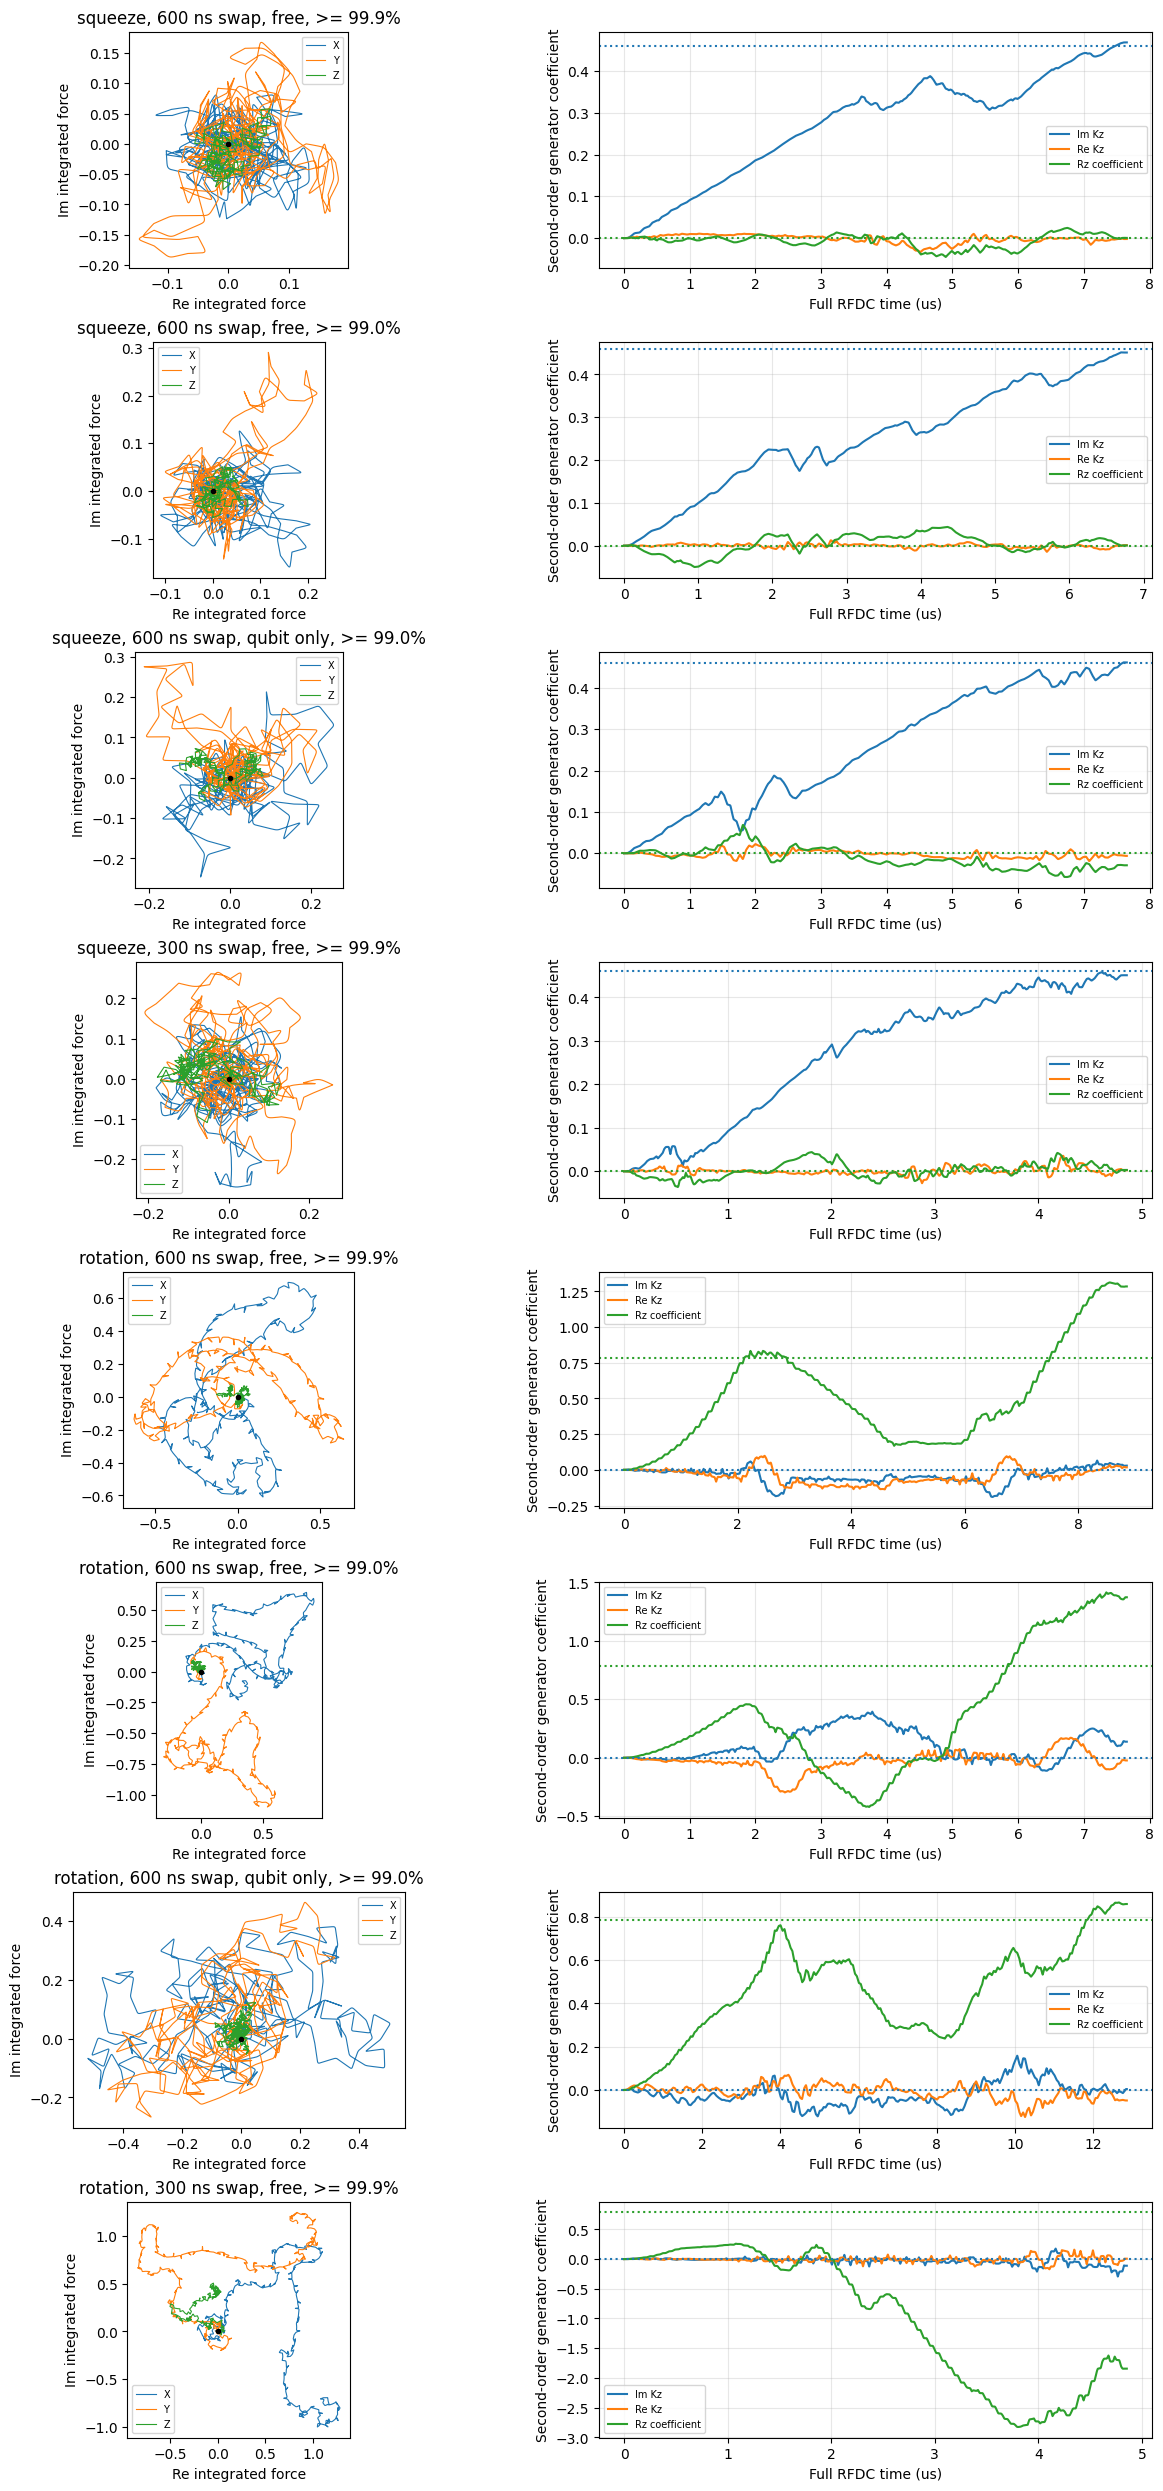

,gate,first_order_norm,Im_Kz,Re_Kz,Rz_coefficient
0,"squeeze, 600 ns swap, free, >= 99.9%",0.009034,0.468354,-0.002115,0.000483
1,"squeeze, 600 ns swap, free, >= 99.0%",0.011995,0.451219,0.001270,0.000554
2,"squeeze, 600 ns swap, qubit only, >= 99.0%",0.022861,0.461898,-0.006406,-0.029147
3,"squeeze, 300 ns swap, free, >= 99.9%",0.018040,0.450940,0.002492,0.003117
4,"rotation, 600 ns swap, free, >= 99.9%",0.330478,0.029562,0.017521,1.285059
5,"rotation, 600 ns swap, free, >= 99.0%",0.727101,0.137783,-0.022760,1.372820
6,"rotation, 600 ns swap, qubit only, >= 99.0%",0.174638,0.004262,-0.048486,0.858548
7,"rotation, 300 ns swap, free, >= 99.9%",2.034251,-0.112012,0.006274,-1.843819


In [3]:
diagnostics=[]
fig,axes=plt.subplots(len(final),2,figsize=(12,3.1*len(final)),constrained_layout=True)
for row,result in zip(axes,final):
    tr,x=train_of(result,16),controls_of(result)
    diagnostic=cp.toggling_magnus(tr,x)
    first=diagnostic['first'];K=diagnostic['aa'];R=diagnostic['nn'];t=diagnostic['time_us']
    for axis,label in enumerate(['X','Y','Z']):
        row[0].plot(first[:,axis].real,first[:,axis].imag,lw=.8,label=label)
    row[0].plot([0],[0],'ko',ms=3);row[0].set_aspect('equal')
    row[0].set(xlabel='Re integrated force',ylabel='Im integrated force',title=result['job']['label'])
    row[0].legend(fontsize=7)
    row[1].plot(t,K[:,2].imag,label='Im Kz');row[1].plot(t,K[:,2].real,label='Re Kz')
    row[1].plot(t,R[:,2],label='Rz coefficient')
    wanted=(cd.R_8DB/2,0) if result['job']['gate']=='squeeze' else (0,np.pi/4)
    row[1].axhline(wanted[0],ls=':',color='C0');row[1].axhline(wanted[1],ls=':',color='C2')
    row[1].set(xlabel='Full RFDC time (us)',ylabel='Second-order generator coefficient')
    row[1].legend(fontsize=7);row[1].grid(alpha=.3)
    diagnostics.append(dict(gate=result['job']['label'],first_order_norm=float(np.linalg.norm(first[-1])),
                            Im_Kz=K[-1,2].imag,Re_Kz=K[-1,2].real,Rz_coefficient=R[-1,2]))
plt.show()
display(pd.DataFrame(diagnostics))

**Interpretation.** The force paths and second-order coefficients describe the fitted sequence in a specified interaction frame. A final phase list can use first-order motion, all three qubit axes and higher-order corrections, especially during the 30 ns pulses. Agreement of one plotted coefficient with a target is supporting evidence, not a derivation of the full gate. The gate certificate below is the independent all-input unitary comparison.

## 4. Fidelity and verification

Inputs are g/e × n=0…8. We use $F=|\operatorname{Tr}(T^\dagger W)|^2/18^2$ with a single common qubit $R_z$; all relative input phases count. This is coherent process fidelity, not a worst-input guarantee or an average of the separate basis-state fidelities. No output is projected or renormalized. The exact target is constructed independently of the pulse optimiser.

The corrected SDK words and RFDC chain are replayed with fixed stored frames. Both target and output columns must change by less than 1e-9 in norm when the photon cutoff increases. An independent general C++ solver checks every accepted output amplitude. The audit covers all 16 original Gaussian/CD gates: 320 input columns and 90,240 complex amplitudes. It also verifies all 12 gradient directions and 1,728 independent target amplitudes.

## 5. What is optimized, and how

For each fixed (gate, strength, swap, integer number of cells, sampled gap), the original search varies **only the qubit and pump phases**, all 2N angles for a free train. The 30 ns envelope, pi area and pump magnitude stay fixed. L-BFGS-B uses the exact adjoint gradient of the **unfiltered cell-matrix model**. The best common closing qubit Z is eliminated analytically. Seeds are reproducible random phases or the paired commutator construction. A separate discrete outer grid selects N/gap/swap and tied-phase families; these are not simultaneous continuous fit variables.

The original cell model is a design surrogate. All 1,241 stored search results are now independently scored through corrected SDK+RFDC playback at their recorded search cutoff. Search figures use those replay scores. Every accepted gate then receives the stronger cutoff/independent-solver check. The new reusable-CD optimisation in the companion notebook directly uses the SDK+RFDC objective and shared motif parameters across several strengths.

In [4]:
result = final[0]
tr, x = train_of(result), controls_of(result)
c, g = tr.infidelity(x)
v = np.random.default_rng(1).normal(size=len(x)); v /= np.linalg.norm(v)
fd = (tr.infidelity(x + 1e-6 * v, False) - tr.infidelity(x - 1e-6 * v, False)) / 2e-6
print(f"gradient along a random direction: exact {g @ v:.6e}, finite difference {fd:.6e}")
import time
for gate in ("squeeze", "rotation"):
    r = [f for f in final if f["job"]["gate"] == gate][0]
    for levels in (LEVELS[gate], 192):
        t0 = time.time(); F = train_of(r, levels).report(controls_of(r))["fidelity"]
        print(f"{gate:8s} {r['cells']} pulses, {levels:3d} photon levels: F = {F:.10f}  ({time.time() - t0:.2f} s incl. setup)")
t0 = time.time(); [tr.infidelity(x) for _ in range(5)]
print(f"one evaluation with gradient, {tr.cells} cells: {(time.time() - t0) / 5:.3f} s")

gradient along a random direction: exact 1.029871e-05, finite difference 1.029893e-05
squeeze  160 pulses,  96 photon levels: F = 0.9993036961  (0.18 s incl. setup)


squeeze  160 pulses, 192 photon levels: F = 0.9993037395  (1.09 s incl. setup)
rotation 160 pulses,  48 photon levels: F = 0.9996818539  (0.03 s incl. setup)


rotation 160 pulses, 192 photon levels: F = 0.9996818539  (1.08 s incl. setup)


one evaluation with gradient, 160 cells: 0.366 s


## 6. How short can each gate be?

Every optimisation, as gate fidelity against gate time. **Left: no gaps** (π pulses back to back), for three sideband strengths. **Right: today's 600 ns swap with gaps** (fewer π pulses, sideband-only time between them), coloured by the number of π pulses. Each point is the best of its starts.

545 optimisations, 897,922 fidelity evaluations, 14.6 CPU hours


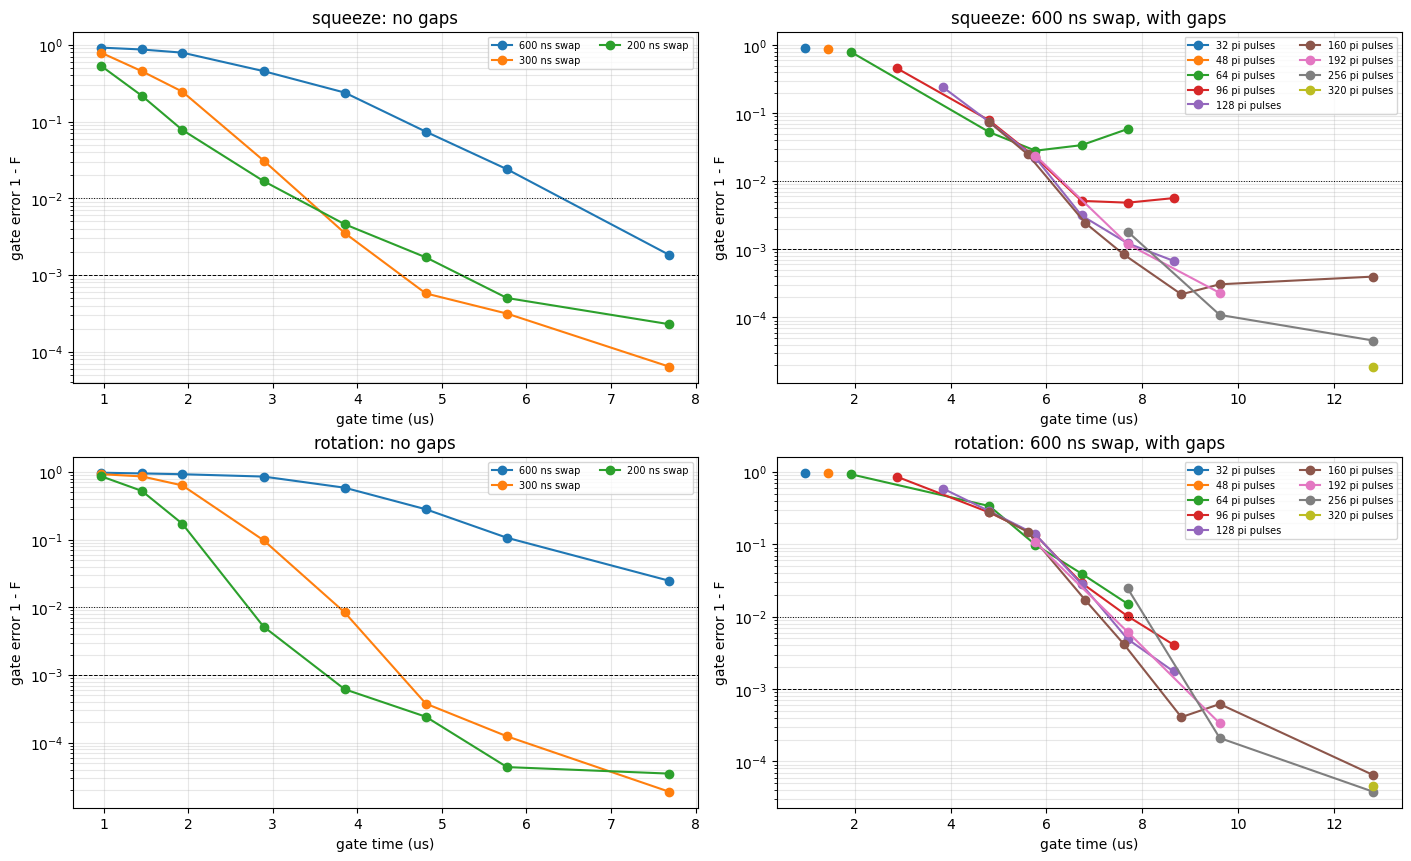

In [5]:
rows = []
for name, data in runs.items():
    for result_index,r in enumerate(data):
        rows.append(dict(source=name, gate=r["job"]["gate"], swap=round(r["swap_ns"]), cells=r["cells"], gap=r["gap_ns"],
                         kind=r["job"]["kind"] + (str(r["job"].get("motif")) if r["job"].get("motif") else ""),
                         study=r["job"].get("study", "sweep"), start=r["job"]["start"], time_us=r["time_us"], F=played_lookup[(name,result_index)], F_design=r["fidelity"],
                         worst=r["worst_input_fidelity"], evaluations=r["evaluations"], seconds=r["seconds"]))
allruns = pd.DataFrame(rows)
allruns.to_csv(f"{RUNS}/all_runs.csv", index=False)
print(f"{len(allruns)} optimisations, {allruns.evaluations.sum():,} fidelity evaluations, "
      f"{allruns.seconds.sum() / 3600:.1f} CPU hours")

free = allruns[allruns.kind == "free"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5), constrained_layout=True)
for row, gate in zip(axes, ("squeeze", "rotation")):
    d = free[(free.gate == gate) & (free.gap == 0)].groupby(["swap", "time_us"]).F.max().reset_index()
    for swap, colour in ((600, "C0"), (300, "C1"), (200, "C2")):
        e = d[d.swap == swap]
        row[0].plot(e.time_us, 1 - e.F, "o-", color=colour, label=f"{swap} ns swap")
    d = free[(free.gate == gate) & (free.swap == 600)].groupby(["cells", "gap", "time_us"]).F.max().reset_index()
    for cells, e in d.groupby("cells"):
        row[1].plot(e.time_us, 1 - e.F, "o-", label=f"{cells} pi pulses")
    for ax, title in zip(row, ("no gaps", "600 ns swap, with gaps")):
        ax.set_yscale("log"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=7, ncol=2)
        ax.axhline(1e-2, color="k", lw=0.7, ls=":"); ax.axhline(1e-3, color="k", lw=0.7, ls="--")
        ax.set_xlabel("gate time (us)"); ax.set_ylabel("gate error 1 - F"); ax.set_title(f"{gate}: {title}")
plt.show()

**Reading.**

* **No gaps, today's 600 ns swap:** the squeeze reaches 99.8 % in 7.69 µs (256 pulses); the rotation only 97.5 %.
* **Stronger sideband, no gaps:** with a 300 ns swap both gates pass 99.9 % in 4.81 µs. With a 200 ns swap the rotation passes 99.9 % in 3.85 µs, but the squeeze is not faster than at 300 ns: there the 30 ns π pulse is no longer short compared with the sideband dynamics.
* **Gaps at 600 ns (right):** at the same gate time, 128–160 π pulses with gaps beat 256 pulses back to back; 64 or 96 pulses level off. Shortest gates: squeeze 99 % in 6.73 µs and 99.9 % in 7.61 µs; rotation 99 % in 7.61 µs and 99.9 % in 8.81 µs.
* **Optimiser convergence matters.** The first sweep stopped at 1500 iterations; continuing the same runs to 5000 iterations raised, for example, the 300 ns, 160-pulse squeeze from 99.81 % to 99.93 %. All final gates are polished with up to 20000 iterations. Different starts can reach different local minima; the plotted score keeps the best recorded start. No global minimum time is established.

## 7. Does structure help? (lessons from the Z2 trains)

Same gate time, five ways to parametrise the phases, 3 random starts each:

* **free**: all 2N phases;
* **palindrome**: cell $j$ and cell $N+1-j$ equal (half the phase parameters; exact waveform time symmetry is not assumed);
* **motif 16 / 32**: one block of 16 or 32 cells repeated;
* **qubit only**: the sideband phase is constant; only the qubit phases change (half the parameters, and a simpler waveform).

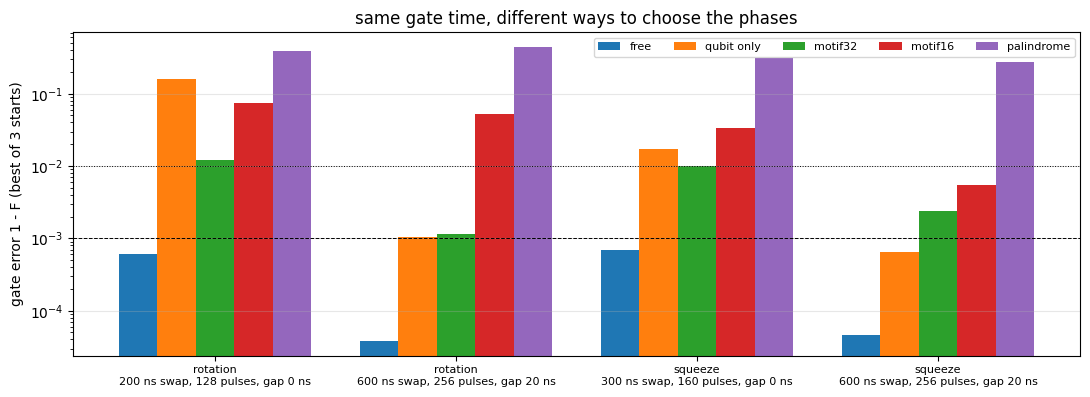

In [6]:
s = allruns[allruns.study == "structure"]
best = s.groupby(["gate", "swap", "cells", "gap", "kind"]).F.max().reset_index()
kinds = ["free", "qubit only", "motif32", "motif16", "palindrome"]
points = best[["gate", "swap", "cells", "gap"]].drop_duplicates().values.tolist()
fig, ax = plt.subplots(figsize=(13, 4.2))
width = 0.16
for i, kind in enumerate(kinds):
    errors = [1 - best[(best.gate == g) & (best.swap == sw) & (best.cells == c) & (best.gap == gp) & (best.kind == kind)].F.iloc[0]
              for g, sw, c, gp in points]
    ax.bar(np.arange(len(points)) + (i - 2) * width, errors, width, label=kind)
ax.set_xticks(range(len(points)), [f"{g}\n{sw:.0f} ns swap, {c} pulses, gap {gp:.0f} ns" for g, sw, c, gp in points], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("gate error 1 - F (best of 3 starts)"); ax.grid(alpha=0.3, axis="y")
ax.axhline(1e-2, color="k", lw=0.7, ls=":"); ax.axhline(1e-3, color="k", lw=0.7, ls="--"); ax.legend(fontsize=8, ncol=5)
ax.set_title("same gate time, different ways to choose the phases")
plt.show()

**What the tested parameterizations found.** Free phases generally give the smallest errors in this finite search. Fixed pump phase can work for longer Gaussian gates; repeated motifs and tied palindromes were less successful at these tested durations. These are local search outcomes, not proofs that a family cannot work.

A palindrome of phase labels is not an exact time symmetry of the sampled finite-drive Hamiltonian: the Hann samples and its qubit toggling frame also matter. Even a symmetry that removes even Magnus orders in one frame does not by itself prove that the desired gate is absent in every frame. We therefore do not explain the failed palindrome fits by claiming that they rigorously cancel the required squeezing term.

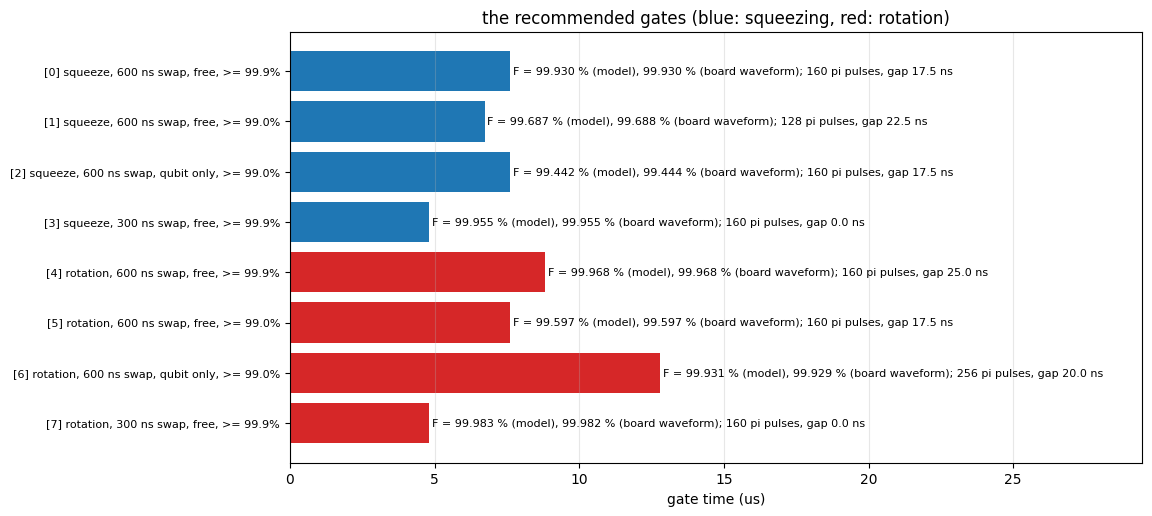

In [7]:
summary = pd.DataFrame([dict(gate=r["job"]["label"], pulses=r["cells"], gap_ns=r["gap_ns"], time_us=r["time_us"],
                             F_model=r["at_192_levels"]["fidelity"], worst_input=r["at_192_levels"]["worst_input_fidelity"],
                             F_board_waveform=r["hardware_check"]["fidelity"],
                             qubit_Rz_after=r["qubit_frame_Rz"],
                             found_from=f"{r['job']['found_in']}, {r['job']['found_start']}", evaluations=r["evaluations"])
                        for r in final])
summary.to_csv(f"{RUNS}/final_gates.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 0.55 * len(summary) + 1.2))
for i, r in summary.iterrows():
    ax.barh(i, r.time_us, color="C0" if r.gate.startswith("squeeze") else "C3")
    ax.text(r.time_us + 0.1, i, f"F = {100 * r.F_model:.3f} % (model), {100 * r.F_board_waveform:.3f} % (board waveform); "
            f"{r.pulses} pi pulses, gap {r.gap_ns:.1f} ns", va="center", fontsize=8)
ax.set_yticks(range(len(summary)), [f"[{i}] {g}" for i, g in enumerate(summary.gate)], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("gate time (us)"); ax.set_xlim(0, summary.time_us.max() * 2.3); ax.grid(alpha=0.3, axis="x")
ax.set_title("the recommended gates (blue: squeezing, red: rotation)")
plt.show()

`F_model`: the optimiser's model at 192 photon levels. `F_board_waveform`: the same phases played through the real chain (`hardware_check.py`): converted to the SDK's 16-bit I/Q words at the calibrated DAC scales, passed through the converter's 8× interpolation filter (with its start-up and tail), and integrated sample by sample at 6.4 GS/s by an independent C++ propagator, with the qubit frame correction fixed (nothing re-fitted) and the photon cutoff raised until converged. `qubit_Rz_after` (rad) is the qubit frame update to apply after the gate: $R_z(\zeta) = e^{-i\zeta\sigma_z/2}$.

### Gate [0]: 8 dB squeezing, 600 ns swap, 7.61 µs, 99.93 % (recommended)

How it was found and its fidelities are printed first. Figures: (1) the whole pulse sequence: qubit π pulses (top line of each row) and sideband cells (bottom line), coloured by phase, gaps visible; (2) the phase of every π pulse and the drive envelopes; (3) programmed I/Q against what the board outputs, 4 pulses from the middle; (4) the error of each of the 18 inputs (shown separately from the process score, which also counts relative phases); (5) Wigner functions of the cavity in each qubit branch, simulated against ideal, with the measured squeezing (dB, axis) or rotation angles.

squeeze, 600 ns swap, free, >= 99.9%: 160 pi pulses, gap 17.5 ns, 7.61 us
How it was found: random 1 start in round3.json (F = 0.99916), then polished with 15001 more evaluations -> F = 0.999304
Gate fidelity: model 0.999304, board waveform 0.999304 (cutoff 256 levels); worst single input 0.99683
After the gate: qubit Rz(-2.367425 rad)


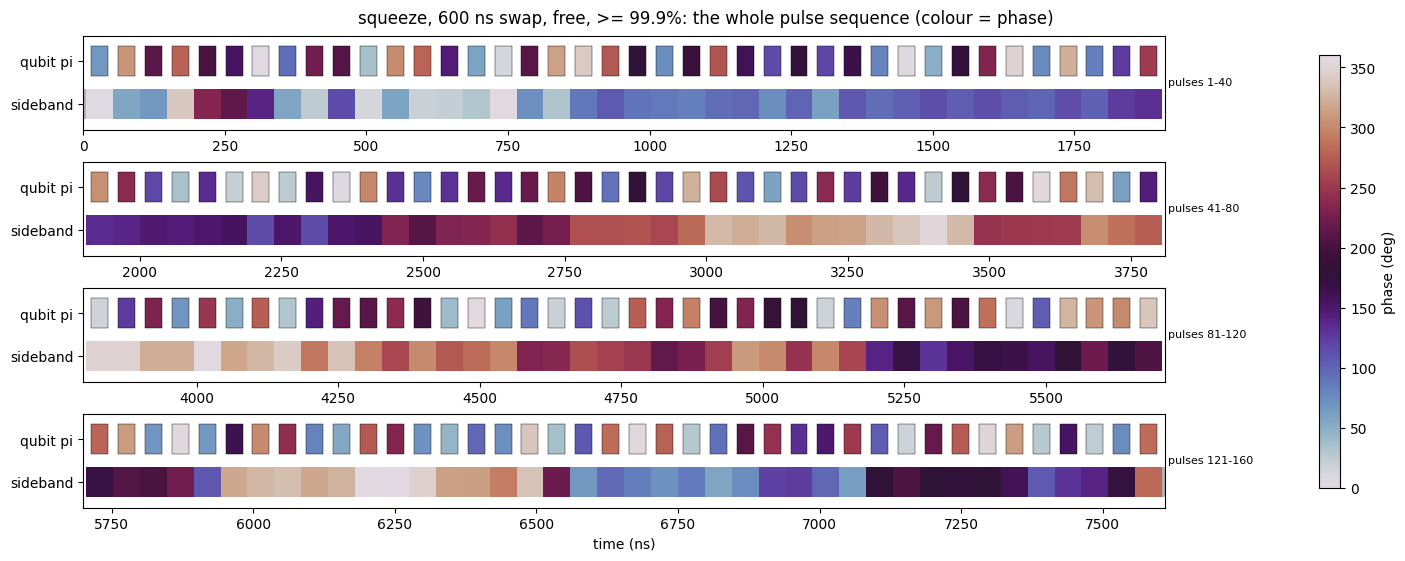

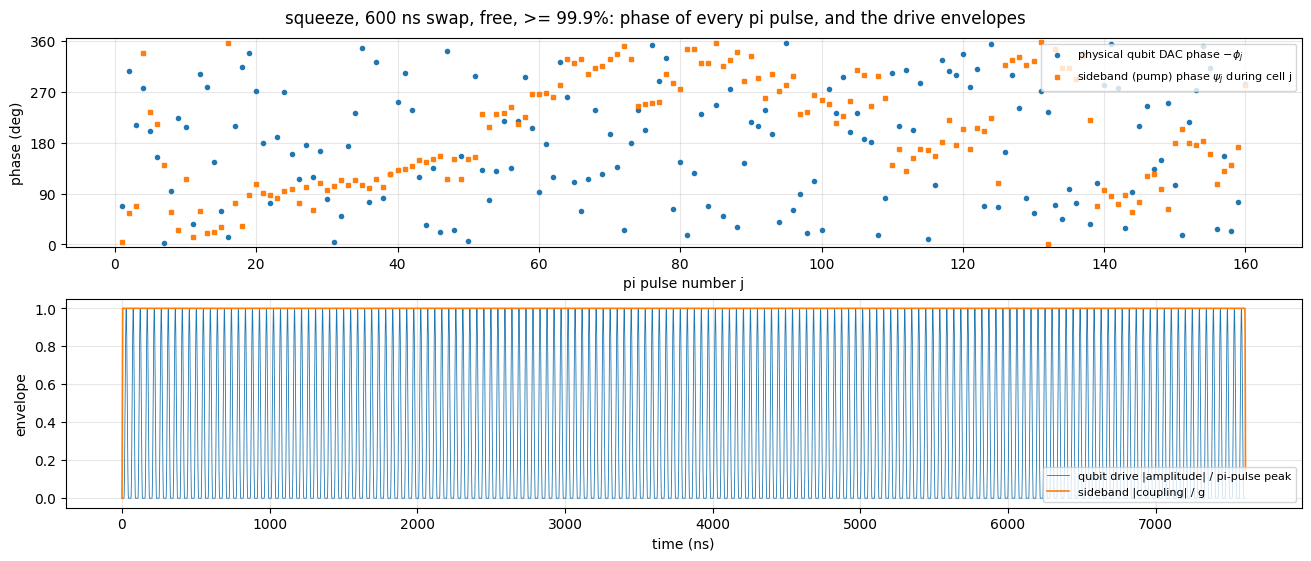

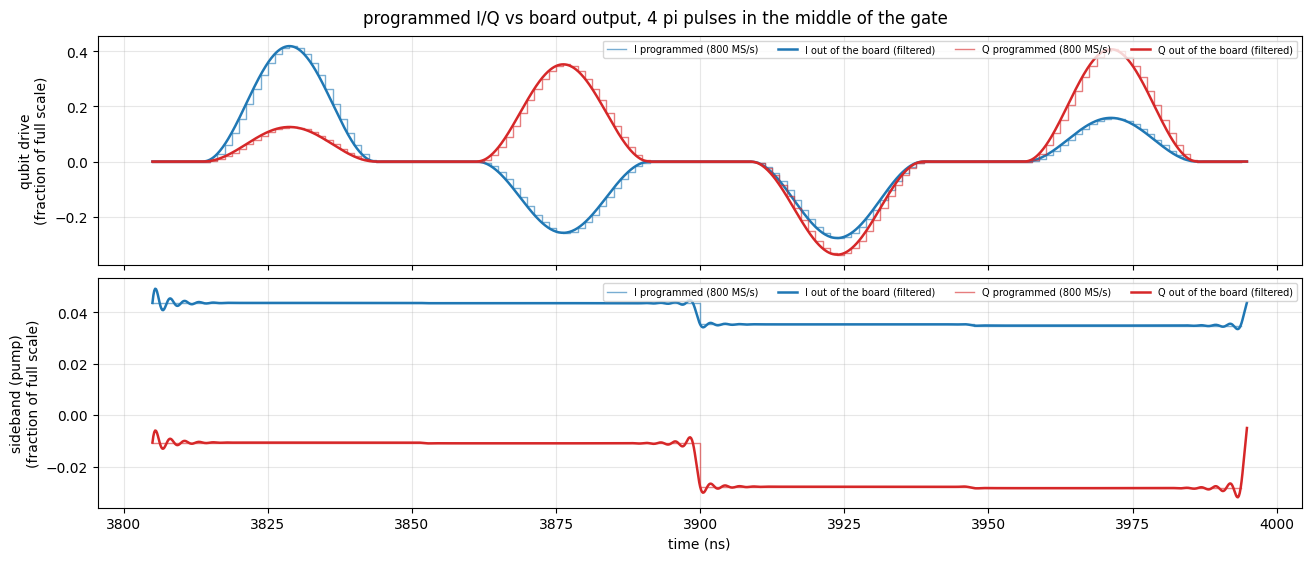

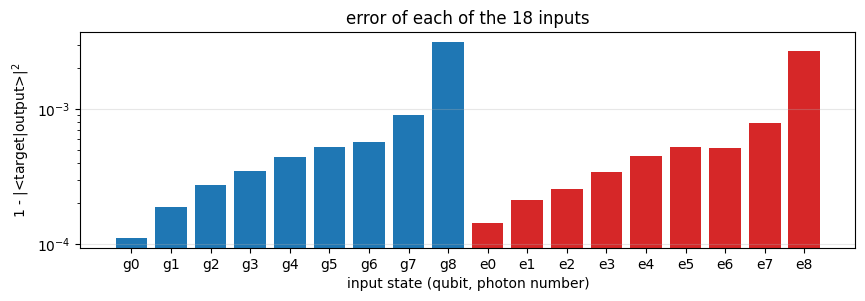

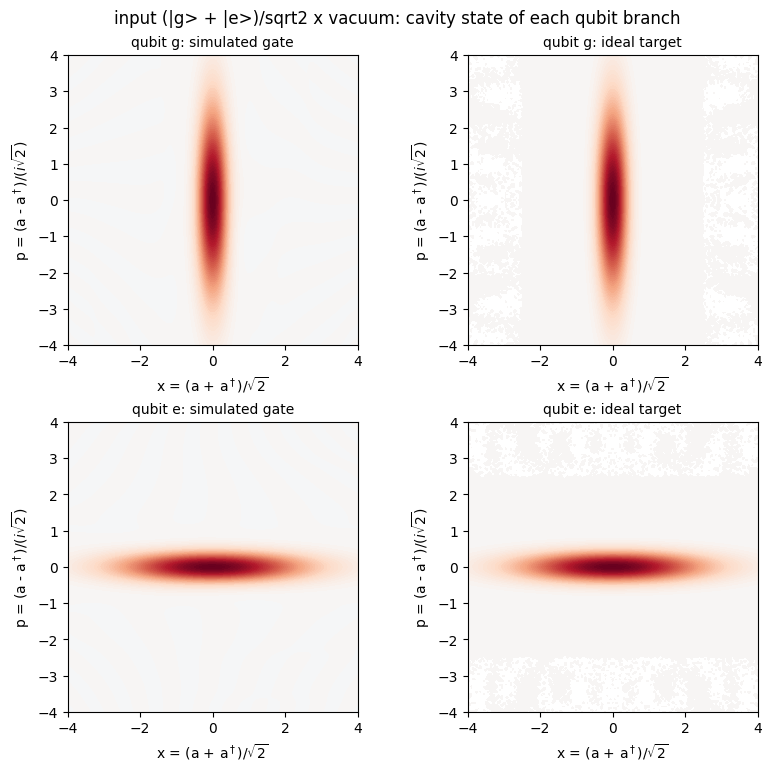

qubit g: squeezing 8.043 dB along +0.05 deg   (target 8.000 dB along +0.00 deg)
qubit e: squeezing 8.019 dB along +89.95 deg   (target 8.000 dB along +90.00 deg)
full sequence (pulse, qubit phase, pump phase) for programming: runs/sequence_0.csv; int16 I/Q words: runs/words_0.npz


In [8]:
result = final[0]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.1f} ns, {result['time_us']:.2f} us")
print(f"How it was found: {job['found_start']} start in {job['found_in']} (F = {job['found_fidelity']:.5f}), then polished "
      f"with {result['evaluations']} more evaluations -> F = {result['fidelity']:.6f}")
print(f"Gate fidelity: model {result['at_192_levels']['fidelity']:.6f}, board waveform {result['hardware_check']['fidelity']:.6f} "
      f"(cutoff {result['hardware_check']['levels']} levels); worst single input {result['at_192_levels']['worst_input_fidelity']:.5f}")
print(f"After the gate: qubit Rz({result['qubit_frame_Rz']:.6f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)")
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=result["cells"] // 2, n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle of the gate")

# per-input fidelity
out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(18), 1 - abs(overlaps) ** 2, color=["C0"] * 9 + ["C3"] * 9)
ax.set_xticks(range(18), [f"g{n}" for n in range(9)] + [f"e{n}" for n in range(9)])
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 18 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# what the gate does
levels = tr.space.levels
if job["gate"] == "squeeze":
    vac = np.zeros(levels); vac[0] = 1
    sim, ideal = cp.wigner_panels(tr, x, vac, "input (|g> + |e>)/sqrt2 x vacuum: cavity state of each qubit branch")
    for branch, s, i in zip("ge", sim, ideal):
        db, angle = cp.squeezing_db(s); db_i, angle_i = cp.squeezing_db(i)
        print(f"qubit {branch}: squeezing {db:.3f} dB along {angle:+.2f} deg   (target {db_i:.3f} dB along {angle_i:+.2f} deg)")
else:
    alpha = 1.5
    sim, ideal = cp.wigner_panels(tr, x, cp.coherent(levels, alpha), f"input (|g> + |e>)/sqrt2 x coherent alpha = {alpha}")
    a = np.diag(np.sqrt(np.arange(1, levels)), 1)
    angles = [np.degrees(np.angle(np.vdot(s, a @ s))) for s in sim]
    print(f"rotation of the coherent state: g branch {angles[0]:+.3f} deg, e branch {angles[1]:+.3f} deg, "
          f"relative {((angles[1] - angles[0]) % 360):.3f} deg (target -90, +90, 180)")

table = pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1),
                          qubit_phase_deg=np.round(np.degrees(x[:result["cells"]]) % 360, 3),
                          pump_phase_deg=np.round(np.degrees(x[result["cells"]:]) % 360, 3)))
table.to_csv(f"{RUNS}/sequence_{0}.csv", index=False)
print(f"full sequence (pulse, qubit phase, pump phase) for programming: {RUNS}/sequence_{0}.csv; "
      f"int16 I/Q words: {RUNS}/{result['words_file']}")

### Gate [1]: 8 dB squeezing, 600 ns swap, 6.73 µs, 99.69 % (fastest above 99 %)

How it was found and its fidelities are printed first. Figures: (1) the whole pulse sequence: qubit π pulses (top line of each row) and sideband cells (bottom line), coloured by phase, gaps visible; (2) the phase of every π pulse and the drive envelopes; (3) programmed I/Q against what the board outputs, 4 pulses from the middle; (4) the error of each of the 18 inputs (shown separately from the process score, which also counts relative phases); (5) Wigner functions of the cavity in each qubit branch, simulated against ideal, with the measured squeezing (dB, axis) or rotation angles.

squeeze, 600 ns swap, free, >= 99.0%: 128 pi pulses, gap 22.5 ns, 6.73 us
How it was found: random 0 start in round3.json (F = 0.99684), then polished with 15001 more evaluations -> F = 0.996874
Gate fidelity: model 0.996874, board waveform 0.996880 (cutoff 256 levels); worst single input 0.98557
After the gate: qubit Rz(6.076183 rad)


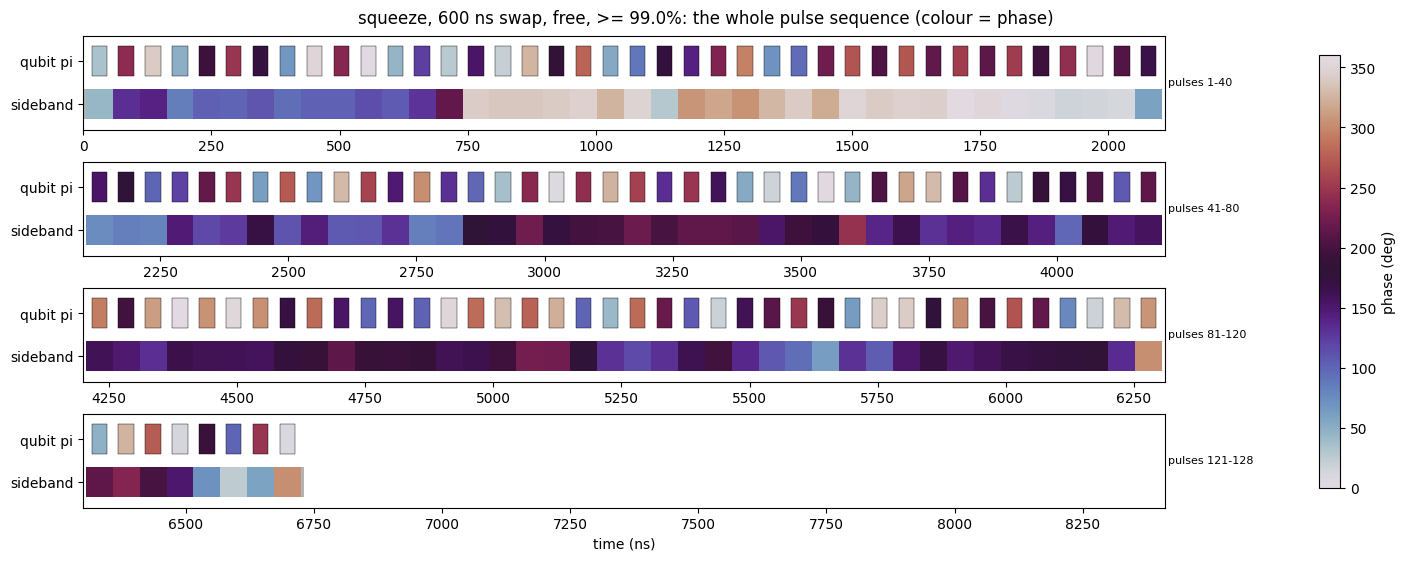

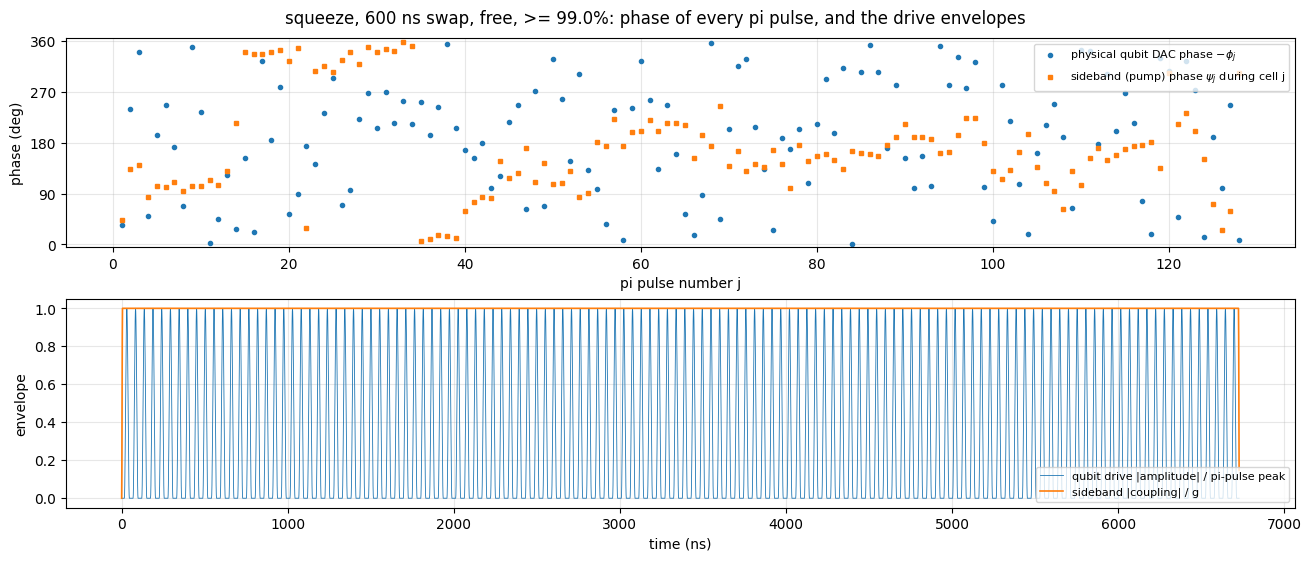

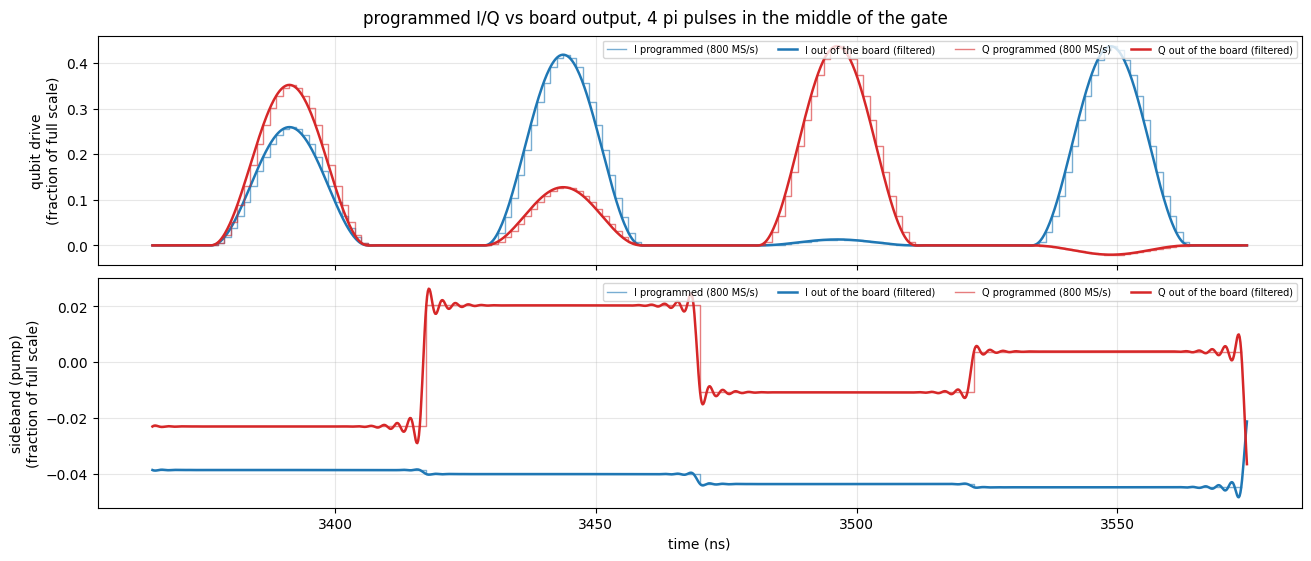

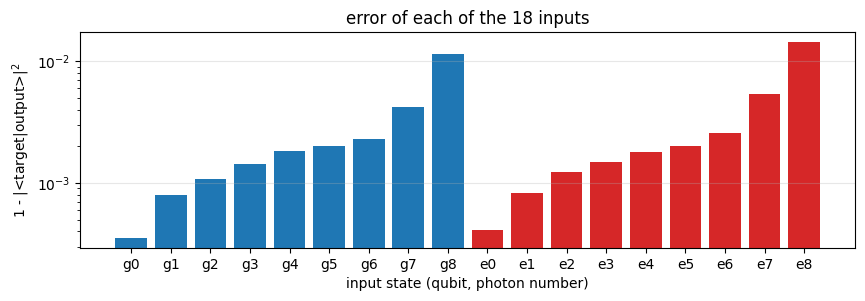

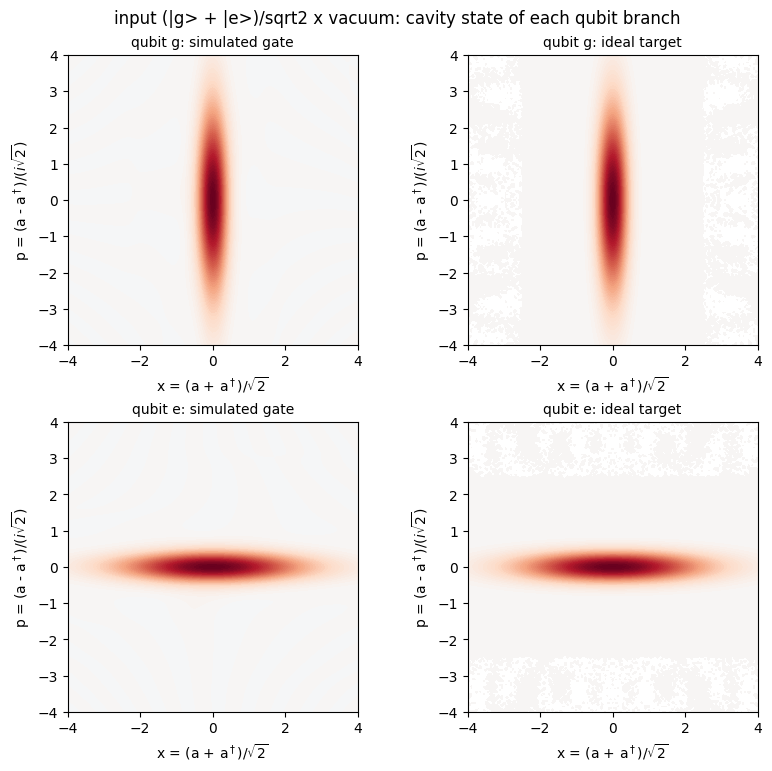

qubit g: squeezing 7.998 dB along +0.10 deg   (target 8.000 dB along +0.00 deg)
qubit e: squeezing 7.877 dB along +89.90 deg   (target 8.000 dB along +90.00 deg)
full sequence (pulse, qubit phase, pump phase) for programming: runs/sequence_1.csv; int16 I/Q words: runs/words_1.npz


In [9]:
result = final[1]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.1f} ns, {result['time_us']:.2f} us")
print(f"How it was found: {job['found_start']} start in {job['found_in']} (F = {job['found_fidelity']:.5f}), then polished "
      f"with {result['evaluations']} more evaluations -> F = {result['fidelity']:.6f}")
print(f"Gate fidelity: model {result['at_192_levels']['fidelity']:.6f}, board waveform {result['hardware_check']['fidelity']:.6f} "
      f"(cutoff {result['hardware_check']['levels']} levels); worst single input {result['at_192_levels']['worst_input_fidelity']:.5f}")
print(f"After the gate: qubit Rz({result['qubit_frame_Rz']:.6f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)")
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=result["cells"] // 2, n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle of the gate")

# per-input fidelity
out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(18), 1 - abs(overlaps) ** 2, color=["C0"] * 9 + ["C3"] * 9)
ax.set_xticks(range(18), [f"g{n}" for n in range(9)] + [f"e{n}" for n in range(9)])
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 18 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# what the gate does
levels = tr.space.levels
if job["gate"] == "squeeze":
    vac = np.zeros(levels); vac[0] = 1
    sim, ideal = cp.wigner_panels(tr, x, vac, "input (|g> + |e>)/sqrt2 x vacuum: cavity state of each qubit branch")
    for branch, s, i in zip("ge", sim, ideal):
        db, angle = cp.squeezing_db(s); db_i, angle_i = cp.squeezing_db(i)
        print(f"qubit {branch}: squeezing {db:.3f} dB along {angle:+.2f} deg   (target {db_i:.3f} dB along {angle_i:+.2f} deg)")
else:
    alpha = 1.5
    sim, ideal = cp.wigner_panels(tr, x, cp.coherent(levels, alpha), f"input (|g> + |e>)/sqrt2 x coherent alpha = {alpha}")
    a = np.diag(np.sqrt(np.arange(1, levels)), 1)
    angles = [np.degrees(np.angle(np.vdot(s, a @ s))) for s in sim]
    print(f"rotation of the coherent state: g branch {angles[0]:+.3f} deg, e branch {angles[1]:+.3f} deg, "
          f"relative {((angles[1] - angles[0]) % 360):.3f} deg (target -90, +90, 180)")

table = pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1),
                          qubit_phase_deg=np.round(np.degrees(x[:result["cells"]]) % 360, 3),
                          pump_phase_deg=np.round(np.degrees(x[result["cells"]:]) % 360, 3)))
table.to_csv(f"{RUNS}/sequence_{1}.csv", index=False)
print(f"full sequence (pulse, qubit phase, pump phase) for programming: {RUNS}/sequence_{1}.csv; "
      f"int16 I/Q words: {RUNS}/{result['words_file']}")

### Gate [2]: 8 dB squeezing, 600 ns swap, constant sideband phase, 7.61 µs, 99.44 %

How it was found and its fidelities are printed first. Figures: (1) the whole pulse sequence: qubit π pulses (top line of each row) and sideband cells (bottom line), coloured by phase, gaps visible; (2) the phase of every π pulse and the drive envelopes; (3) programmed I/Q against what the board outputs, 4 pulses from the middle; (4) the error of each of the 18 inputs (shown separately from the process score, which also counts relative phases); (5) Wigner functions of the cavity in each qubit branch, simulated against ideal, with the measured squeezing (dB, axis) or rotation angles.

squeeze, 600 ns swap, qubit only, >= 99.0%: 160 pi pulses, gap 17.5 ns, 7.61 us
How it was found: random 1 start in round3.json (F = 0.99442), then polished with 7 more evaluations -> F = 0.994420
Gate fidelity: model 0.994419, board waveform 0.994438 (cutoff 256 levels); worst single input 0.97710
After the gate: qubit Rz(-2.957886 rad)


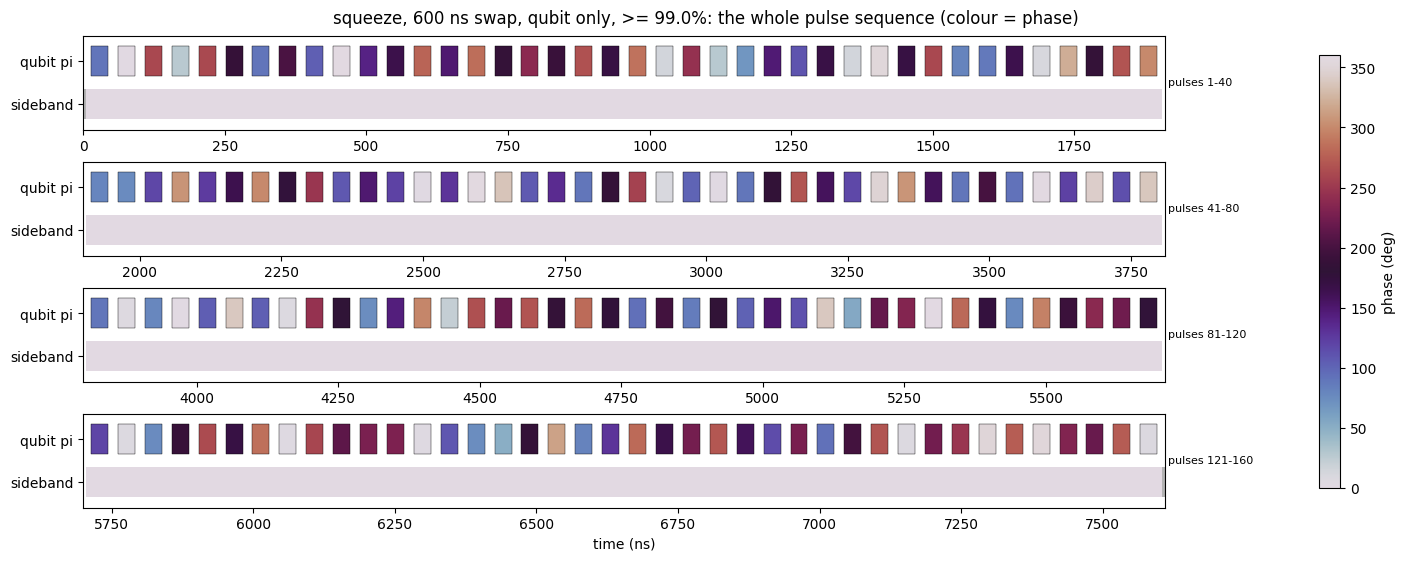

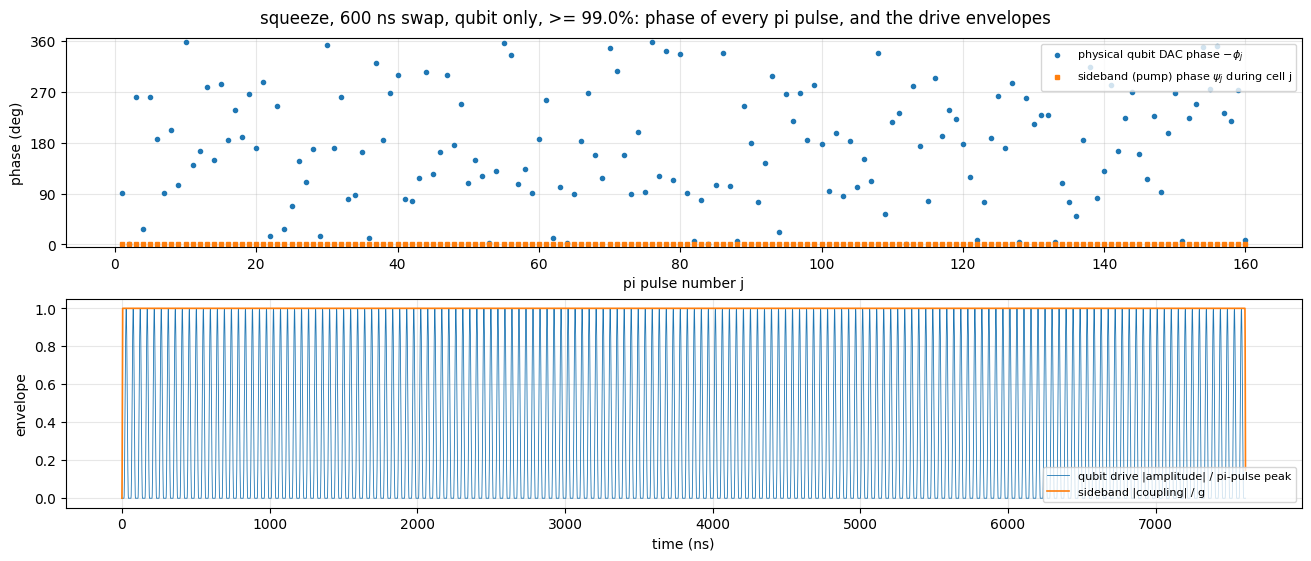

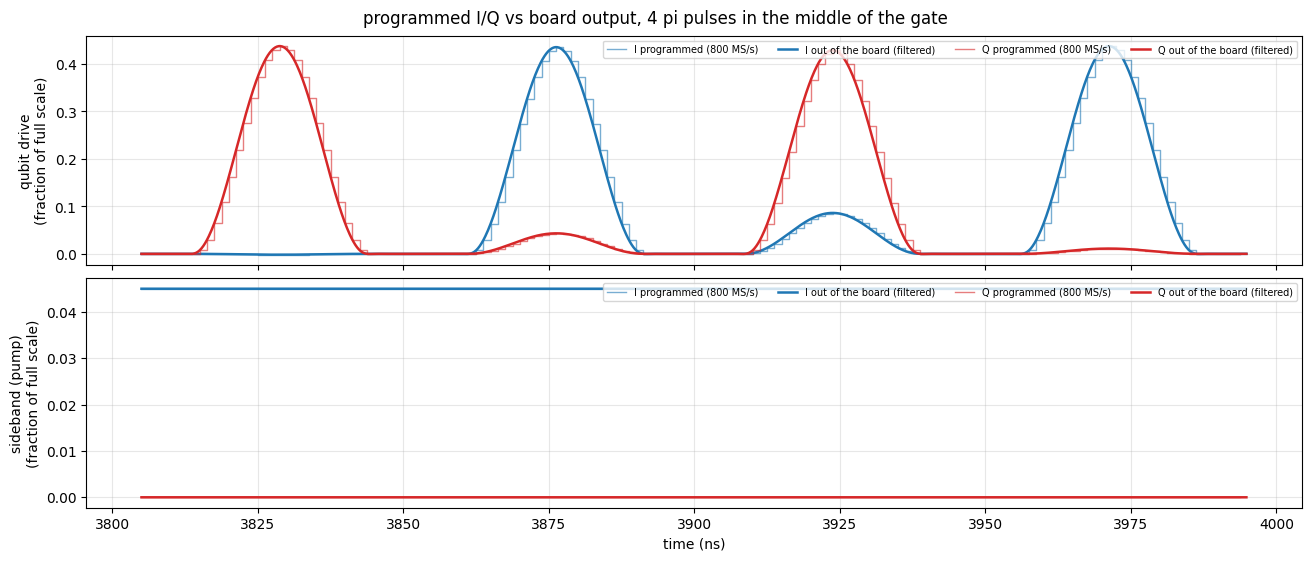

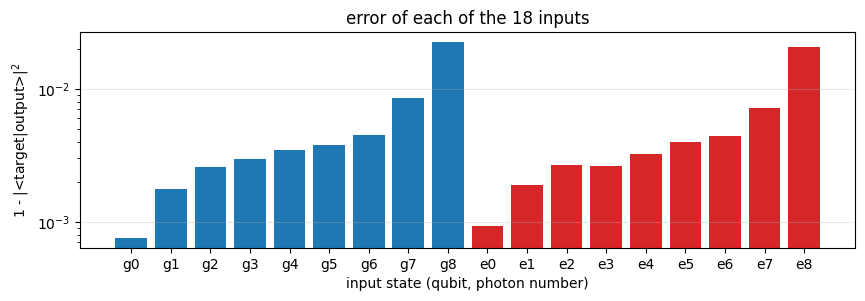

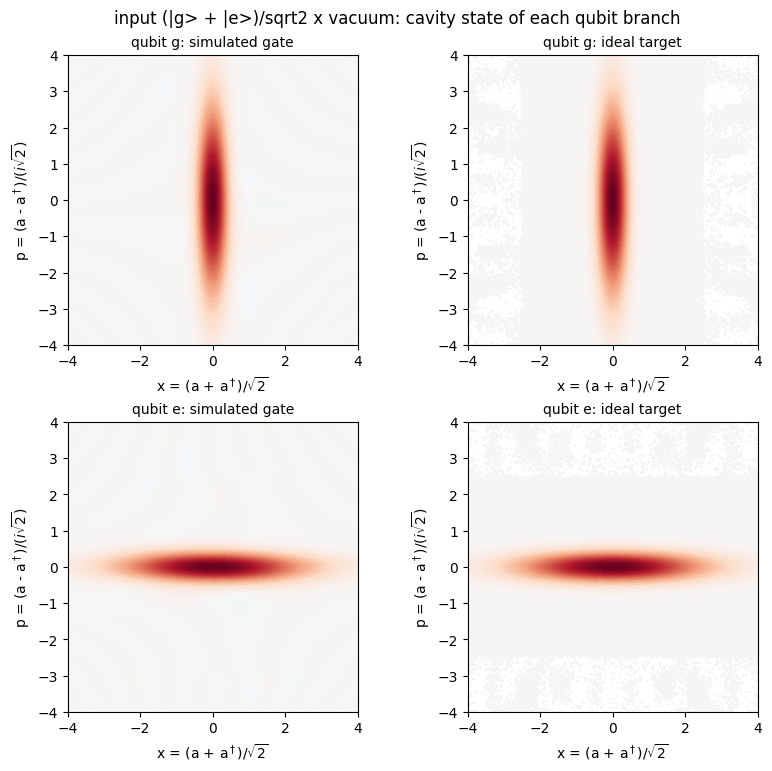

qubit g: squeezing 7.809 dB along +0.10 deg   (target 8.000 dB along +0.00 deg)
qubit e: squeezing 7.832 dB along +89.60 deg   (target 8.000 dB along +90.00 deg)
full sequence (pulse, qubit phase, pump phase) for programming: runs/sequence_2.csv; int16 I/Q words: runs/words_2.npz


In [10]:
result = final[2]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.1f} ns, {result['time_us']:.2f} us")
print(f"How it was found: {job['found_start']} start in {job['found_in']} (F = {job['found_fidelity']:.5f}), then polished "
      f"with {result['evaluations']} more evaluations -> F = {result['fidelity']:.6f}")
print(f"Gate fidelity: model {result['at_192_levels']['fidelity']:.6f}, board waveform {result['hardware_check']['fidelity']:.6f} "
      f"(cutoff {result['hardware_check']['levels']} levels); worst single input {result['at_192_levels']['worst_input_fidelity']:.5f}")
print(f"After the gate: qubit Rz({result['qubit_frame_Rz']:.6f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)")
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=result["cells"] // 2, n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle of the gate")

# per-input fidelity
out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(18), 1 - abs(overlaps) ** 2, color=["C0"] * 9 + ["C3"] * 9)
ax.set_xticks(range(18), [f"g{n}" for n in range(9)] + [f"e{n}" for n in range(9)])
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 18 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# what the gate does
levels = tr.space.levels
if job["gate"] == "squeeze":
    vac = np.zeros(levels); vac[0] = 1
    sim, ideal = cp.wigner_panels(tr, x, vac, "input (|g> + |e>)/sqrt2 x vacuum: cavity state of each qubit branch")
    for branch, s, i in zip("ge", sim, ideal):
        db, angle = cp.squeezing_db(s); db_i, angle_i = cp.squeezing_db(i)
        print(f"qubit {branch}: squeezing {db:.3f} dB along {angle:+.2f} deg   (target {db_i:.3f} dB along {angle_i:+.2f} deg)")
else:
    alpha = 1.5
    sim, ideal = cp.wigner_panels(tr, x, cp.coherent(levels, alpha), f"input (|g> + |e>)/sqrt2 x coherent alpha = {alpha}")
    a = np.diag(np.sqrt(np.arange(1, levels)), 1)
    angles = [np.degrees(np.angle(np.vdot(s, a @ s))) for s in sim]
    print(f"rotation of the coherent state: g branch {angles[0]:+.3f} deg, e branch {angles[1]:+.3f} deg, "
          f"relative {((angles[1] - angles[0]) % 360):.3f} deg (target -90, +90, 180)")

table = pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1),
                          qubit_phase_deg=np.round(np.degrees(x[:result["cells"]]) % 360, 3),
                          pump_phase_deg=np.round(np.degrees(x[result["cells"]:]) % 360, 3)))
table.to_csv(f"{RUNS}/sequence_{2}.csv", index=False)
print(f"full sequence (pulse, qubit phase, pump phase) for programming: {RUNS}/sequence_{2}.csv; "
      f"int16 I/Q words: {RUNS}/{result['words_file']}")

### Gate [3]: 8 dB squeezing, 300 ns swap (2× sideband), 4.81 µs, 99.96 %

How it was found and its fidelities are printed first. Figures: (1) the whole pulse sequence: qubit π pulses (top line of each row) and sideband cells (bottom line), coloured by phase, gaps visible; (2) the phase of every π pulse and the drive envelopes; (3) programmed I/Q against what the board outputs, 4 pulses from the middle; (4) the error of each of the 18 inputs (shown separately from the process score, which also counts relative phases); (5) Wigner functions of the cavity in each qubit branch, simulated against ideal, with the measured squeezing (dB, axis) or rotation angles.

squeeze, 300 ns swap, free, >= 99.9%: 160 pi pulses, gap 0.0 ns, 4.81 us
How it was found: the best no-gap sweep run (random start), continued start in round2.json (F = 0.99943), then polished with 15001 more evaluations -> F = 0.999551
Gate fidelity: model 0.999551, board waveform 0.999549 (cutoff 256 levels); worst single input 0.99812
After the gate: qubit Rz(4.509888 rad)


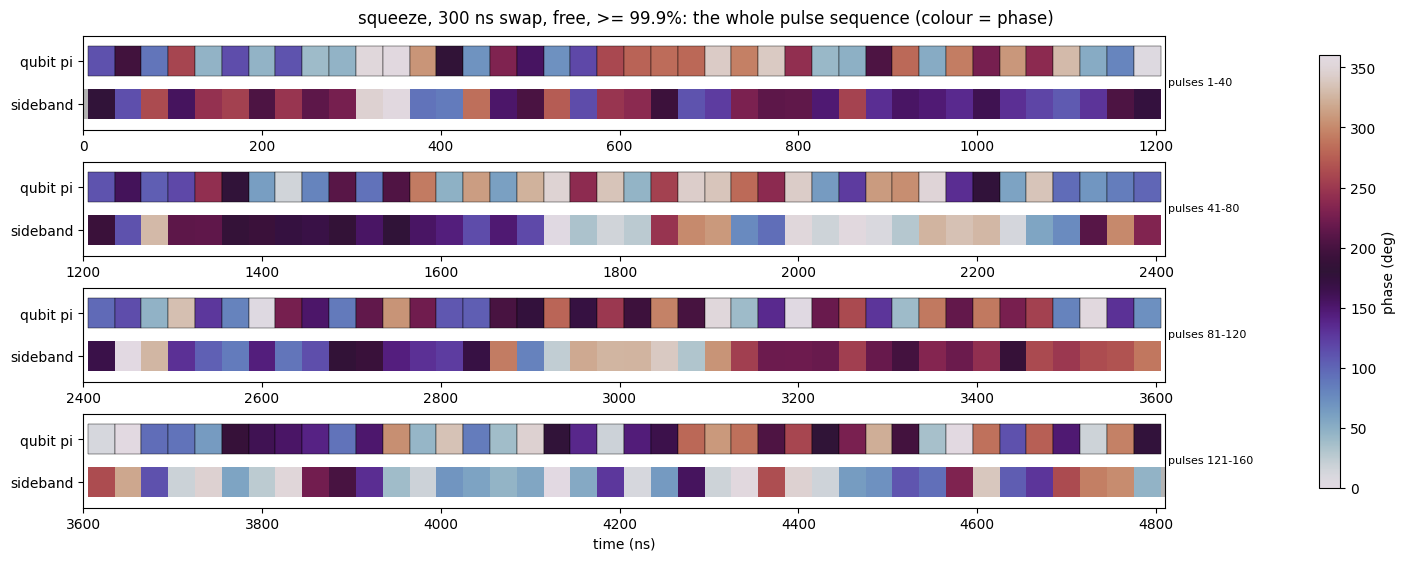

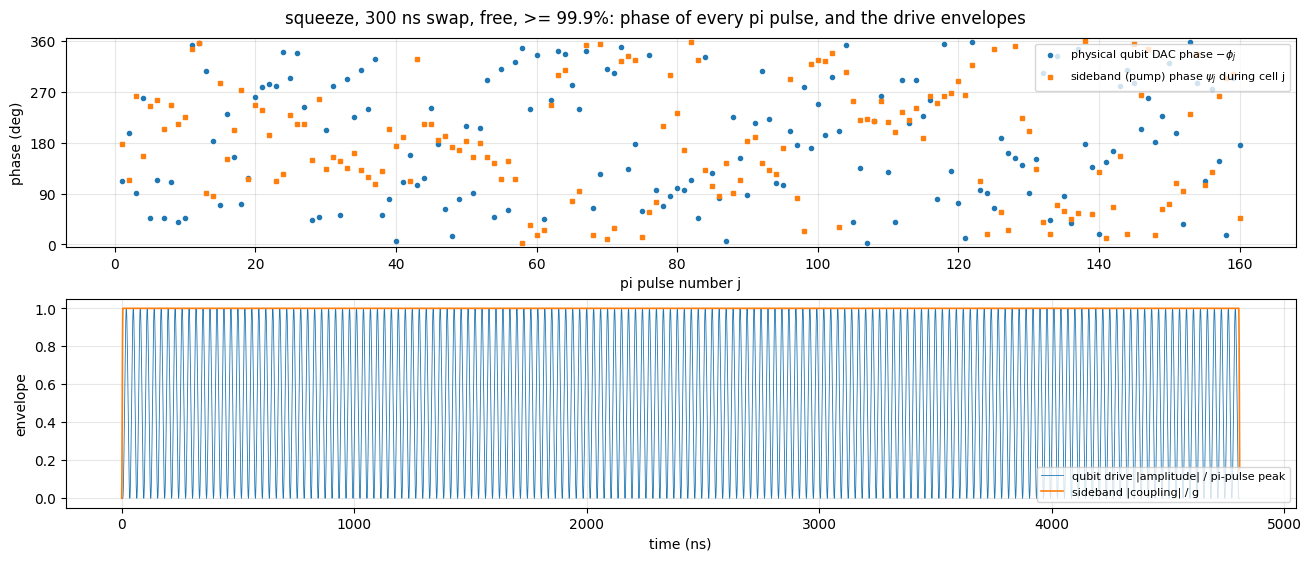

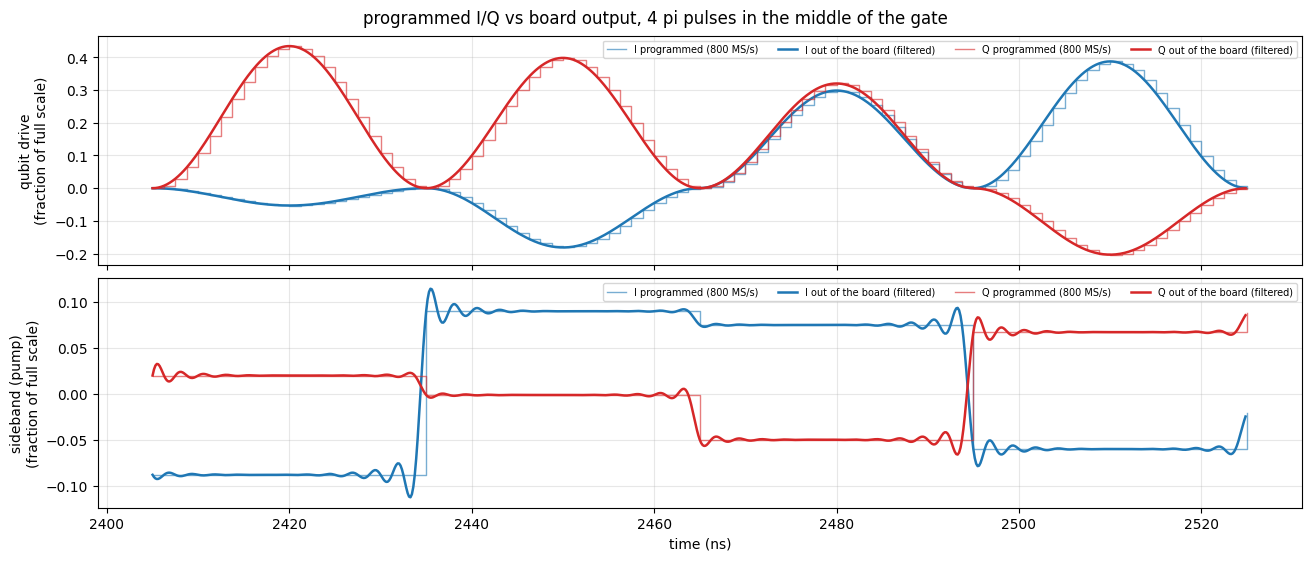

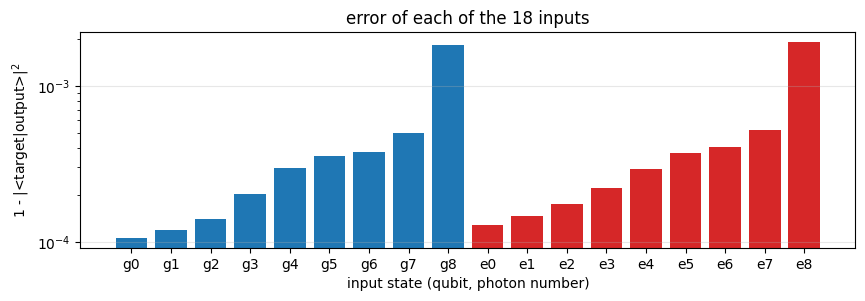

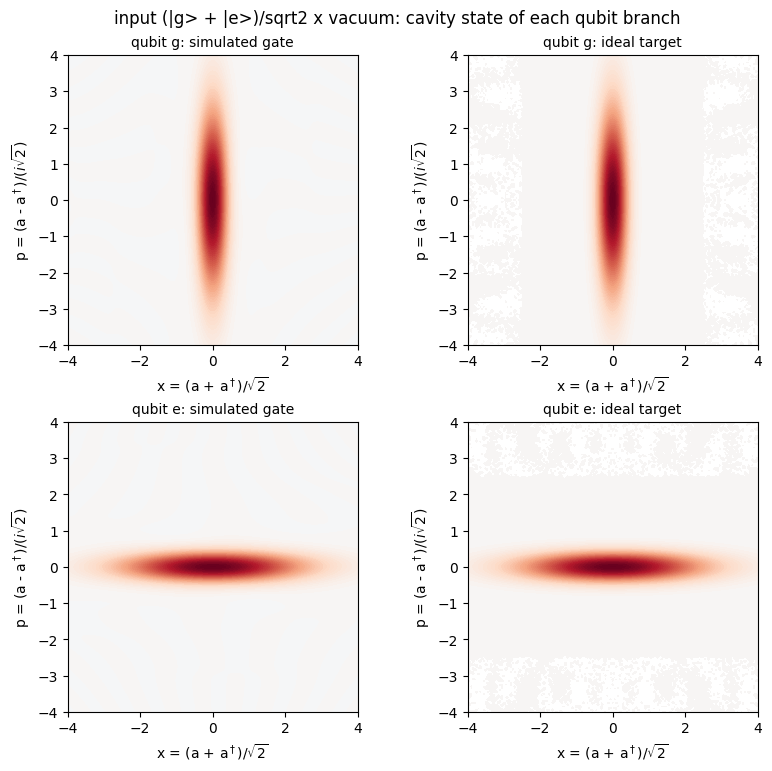

qubit g: squeezing 7.952 dB along +0.00 deg   (target 8.000 dB along +0.00 deg)
qubit e: squeezing 7.915 dB along +90.05 deg   (target 8.000 dB along +90.00 deg)
full sequence (pulse, qubit phase, pump phase) for programming: runs/sequence_3.csv; int16 I/Q words: runs/words_3.npz


In [11]:
result = final[3]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.1f} ns, {result['time_us']:.2f} us")
print(f"How it was found: {job['found_start']} start in {job['found_in']} (F = {job['found_fidelity']:.5f}), then polished "
      f"with {result['evaluations']} more evaluations -> F = {result['fidelity']:.6f}")
print(f"Gate fidelity: model {result['at_192_levels']['fidelity']:.6f}, board waveform {result['hardware_check']['fidelity']:.6f} "
      f"(cutoff {result['hardware_check']['levels']} levels); worst single input {result['at_192_levels']['worst_input_fidelity']:.5f}")
print(f"After the gate: qubit Rz({result['qubit_frame_Rz']:.6f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)")
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=result["cells"] // 2, n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle of the gate")

# per-input fidelity
out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(18), 1 - abs(overlaps) ** 2, color=["C0"] * 9 + ["C3"] * 9)
ax.set_xticks(range(18), [f"g{n}" for n in range(9)] + [f"e{n}" for n in range(9)])
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 18 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# what the gate does
levels = tr.space.levels
if job["gate"] == "squeeze":
    vac = np.zeros(levels); vac[0] = 1
    sim, ideal = cp.wigner_panels(tr, x, vac, "input (|g> + |e>)/sqrt2 x vacuum: cavity state of each qubit branch")
    for branch, s, i in zip("ge", sim, ideal):
        db, angle = cp.squeezing_db(s); db_i, angle_i = cp.squeezing_db(i)
        print(f"qubit {branch}: squeezing {db:.3f} dB along {angle:+.2f} deg   (target {db_i:.3f} dB along {angle_i:+.2f} deg)")
else:
    alpha = 1.5
    sim, ideal = cp.wigner_panels(tr, x, cp.coherent(levels, alpha), f"input (|g> + |e>)/sqrt2 x coherent alpha = {alpha}")
    a = np.diag(np.sqrt(np.arange(1, levels)), 1)
    angles = [np.degrees(np.angle(np.vdot(s, a @ s))) for s in sim]
    print(f"rotation of the coherent state: g branch {angles[0]:+.3f} deg, e branch {angles[1]:+.3f} deg, "
          f"relative {((angles[1] - angles[0]) % 360):.3f} deg (target -90, +90, 180)")

table = pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1),
                          qubit_phase_deg=np.round(np.degrees(x[:result["cells"]]) % 360, 3),
                          pump_phase_deg=np.round(np.degrees(x[result["cells"]:]) % 360, 3)))
table.to_csv(f"{RUNS}/sequence_{3}.csv", index=False)
print(f"full sequence (pulse, qubit phase, pump phase) for programming: {RUNS}/sequence_{3}.csv; "
      f"int16 I/Q words: {RUNS}/{result['words_file']}")

### Gate [4]: rotation (π relative), 600 ns swap, 8.81 µs, 99.97 % (recommended)

How it was found and its fidelities are printed first. Figures: (1) the whole pulse sequence: qubit π pulses (top line of each row) and sideband cells (bottom line), coloured by phase, gaps visible; (2) the phase of every π pulse and the drive envelopes; (3) programmed I/Q against what the board outputs, 4 pulses from the middle; (4) the error of each of the 18 inputs (shown separately from the process score, which also counts relative phases); (5) Wigner functions of the cavity in each qubit branch, simulated against ideal, with the measured squeezing (dB, axis) or rotation angles.

rotation, 600 ns swap, free, >= 99.9%: 160 pi pulses, gap 25.0 ns, 8.81 us
How it was found: random 0 start in round3.json (F = 0.99959), then polished with 15001 more evaluations -> F = 0.999682
Gate fidelity: model 0.999682, board waveform 0.999682 (cutoff 96 levels); worst single input 0.99987
After the gate: qubit Rz(1.061665 rad)


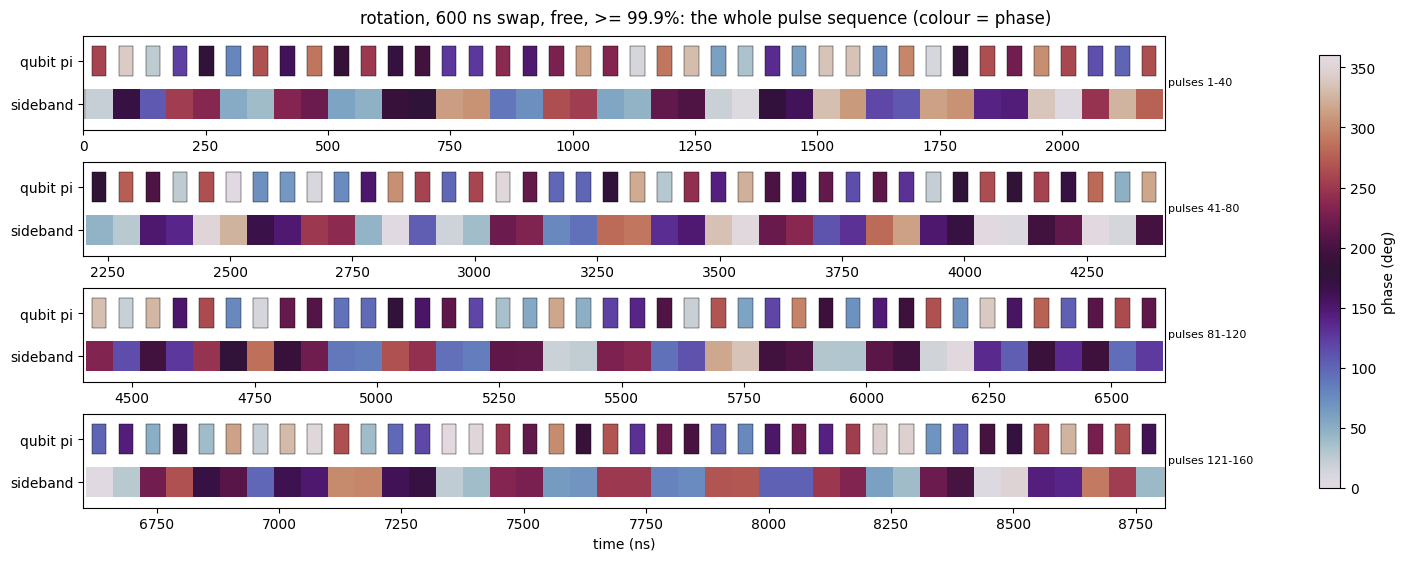

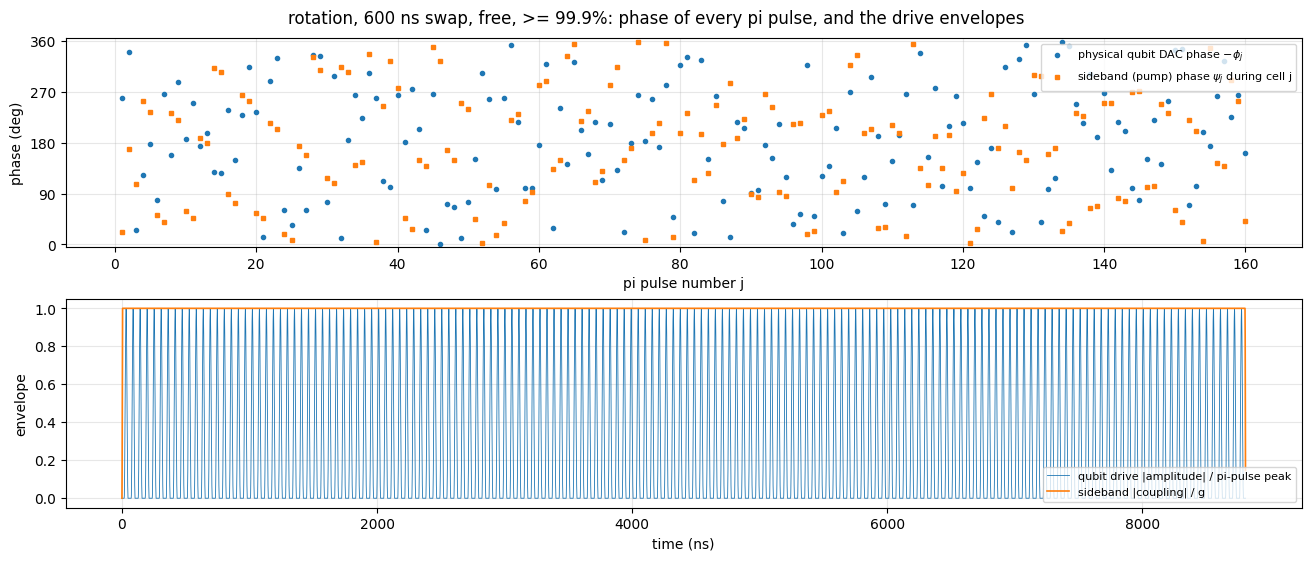

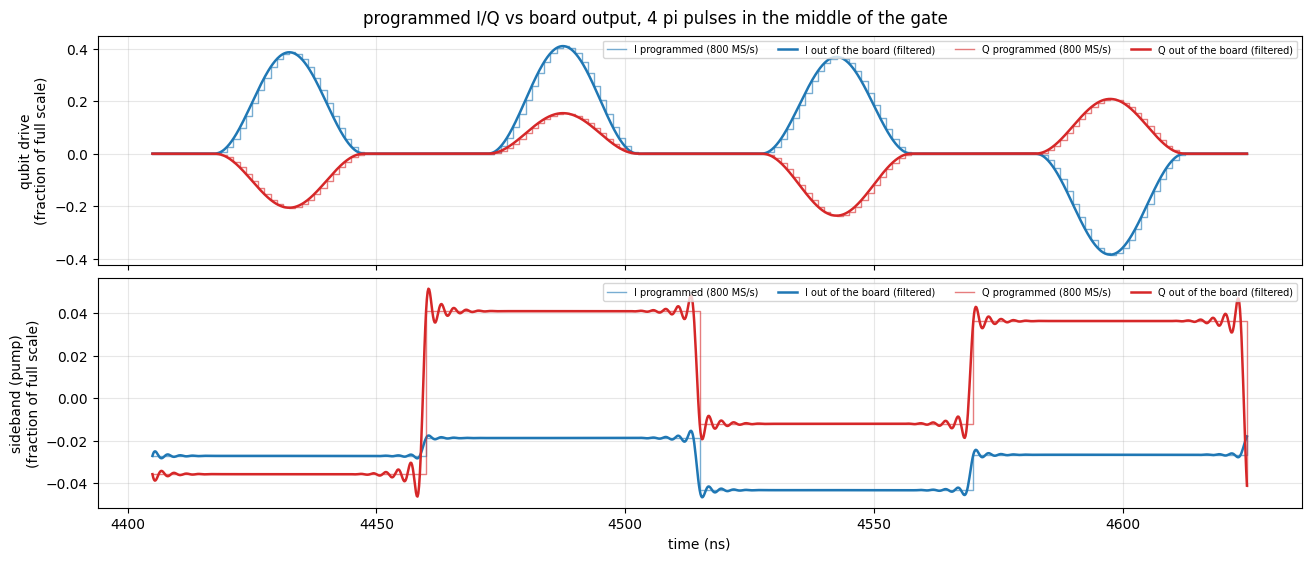

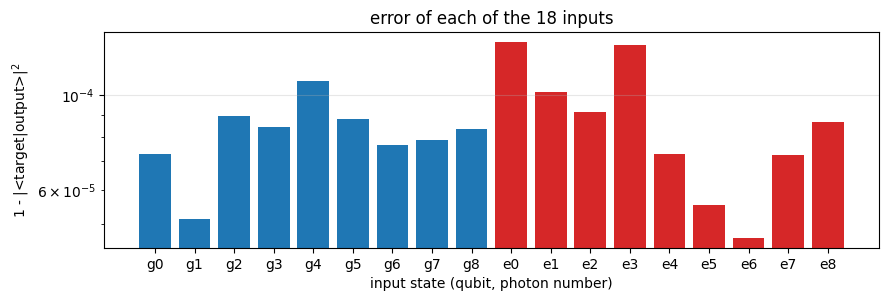

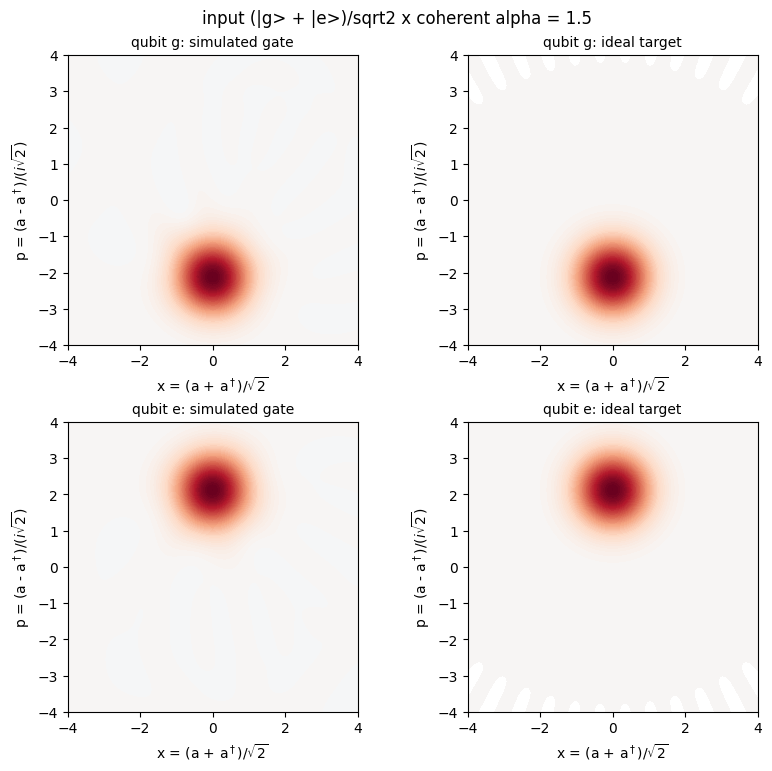

rotation of the coherent state: g branch -90.045 deg, e branch +90.162 deg, relative 180.207 deg (target -90, +90, 180)
full sequence (pulse, qubit phase, pump phase) for programming: runs/sequence_4.csv; int16 I/Q words: runs/words_4.npz


In [12]:
result = final[4]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.1f} ns, {result['time_us']:.2f} us")
print(f"How it was found: {job['found_start']} start in {job['found_in']} (F = {job['found_fidelity']:.5f}), then polished "
      f"with {result['evaluations']} more evaluations -> F = {result['fidelity']:.6f}")
print(f"Gate fidelity: model {result['at_192_levels']['fidelity']:.6f}, board waveform {result['hardware_check']['fidelity']:.6f} "
      f"(cutoff {result['hardware_check']['levels']} levels); worst single input {result['at_192_levels']['worst_input_fidelity']:.5f}")
print(f"After the gate: qubit Rz({result['qubit_frame_Rz']:.6f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)")
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=result["cells"] // 2, n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle of the gate")

# per-input fidelity
out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(18), 1 - abs(overlaps) ** 2, color=["C0"] * 9 + ["C3"] * 9)
ax.set_xticks(range(18), [f"g{n}" for n in range(9)] + [f"e{n}" for n in range(9)])
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 18 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# what the gate does
levels = tr.space.levels
if job["gate"] == "squeeze":
    vac = np.zeros(levels); vac[0] = 1
    sim, ideal = cp.wigner_panels(tr, x, vac, "input (|g> + |e>)/sqrt2 x vacuum: cavity state of each qubit branch")
    for branch, s, i in zip("ge", sim, ideal):
        db, angle = cp.squeezing_db(s); db_i, angle_i = cp.squeezing_db(i)
        print(f"qubit {branch}: squeezing {db:.3f} dB along {angle:+.2f} deg   (target {db_i:.3f} dB along {angle_i:+.2f} deg)")
else:
    alpha = 1.5
    sim, ideal = cp.wigner_panels(tr, x, cp.coherent(levels, alpha), f"input (|g> + |e>)/sqrt2 x coherent alpha = {alpha}")
    a = np.diag(np.sqrt(np.arange(1, levels)), 1)
    angles = [np.degrees(np.angle(np.vdot(s, a @ s))) for s in sim]
    print(f"rotation of the coherent state: g branch {angles[0]:+.3f} deg, e branch {angles[1]:+.3f} deg, "
          f"relative {((angles[1] - angles[0]) % 360):.3f} deg (target -90, +90, 180)")

table = pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1),
                          qubit_phase_deg=np.round(np.degrees(x[:result["cells"]]) % 360, 3),
                          pump_phase_deg=np.round(np.degrees(x[result["cells"]:]) % 360, 3)))
table.to_csv(f"{RUNS}/sequence_{4}.csv", index=False)
print(f"full sequence (pulse, qubit phase, pump phase) for programming: {RUNS}/sequence_{4}.csv; "
      f"int16 I/Q words: {RUNS}/{result['words_file']}")

### Gate [5]: rotation (π relative), 600 ns swap, 7.61 µs, 99.60 % (fastest above 99 %)

How it was found and its fidelities are printed first. Figures: (1) the whole pulse sequence: qubit π pulses (top line of each row) and sideband cells (bottom line), coloured by phase, gaps visible; (2) the phase of every π pulse and the drive envelopes; (3) programmed I/Q against what the board outputs, 4 pulses from the middle; (4) the error of each of the 18 inputs (shown separately from the process score, which also counts relative phases); (5) Wigner functions of the cavity in each qubit branch, simulated against ideal, with the measured squeezing (dB, axis) or rotation angles.

rotation, 600 ns swap, free, >= 99.0%: 160 pi pulses, gap 17.5 ns, 7.61 us
How it was found: random 0 start in round3.json (F = 0.99580), then polished with 15001 more evaluations -> F = 0.995968
Gate fidelity: model 0.995968, board waveform 0.995973 (cutoff 96 levels); worst single input 0.99763
After the gate: qubit Rz(1.904682 rad)


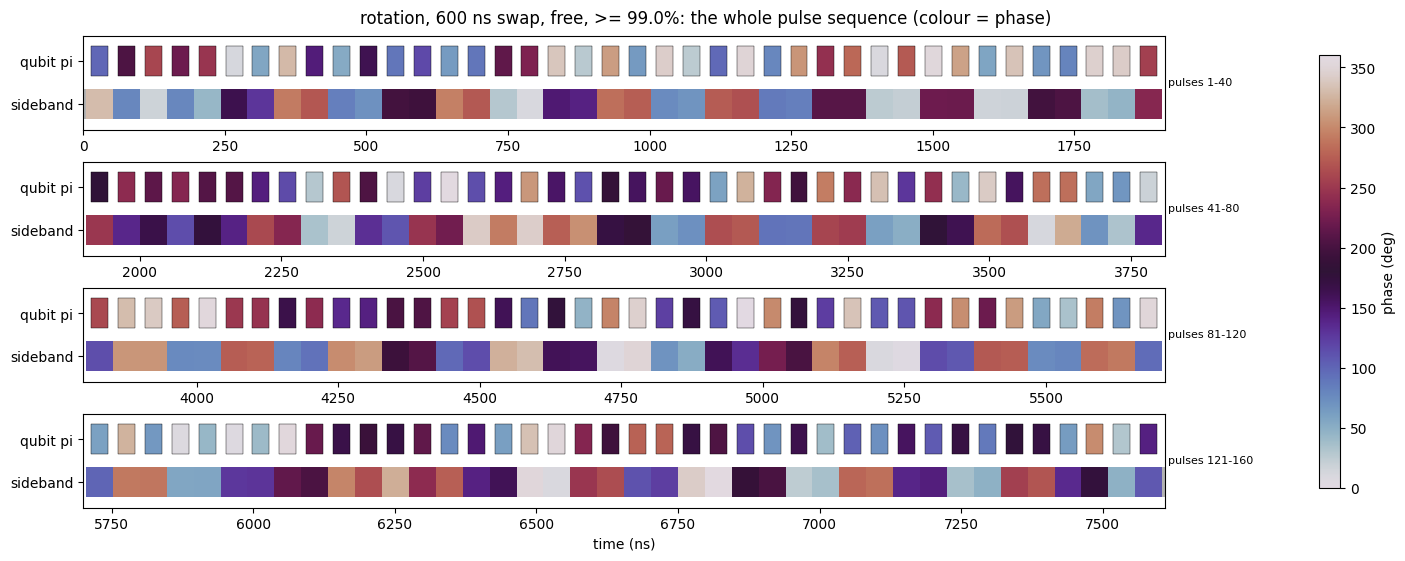

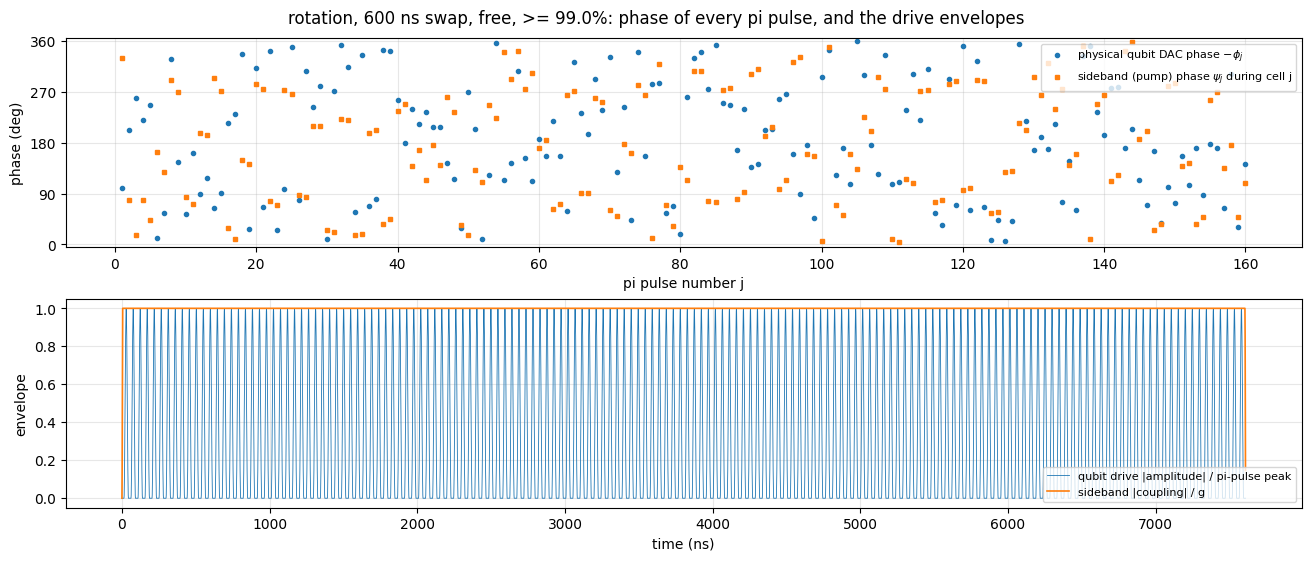

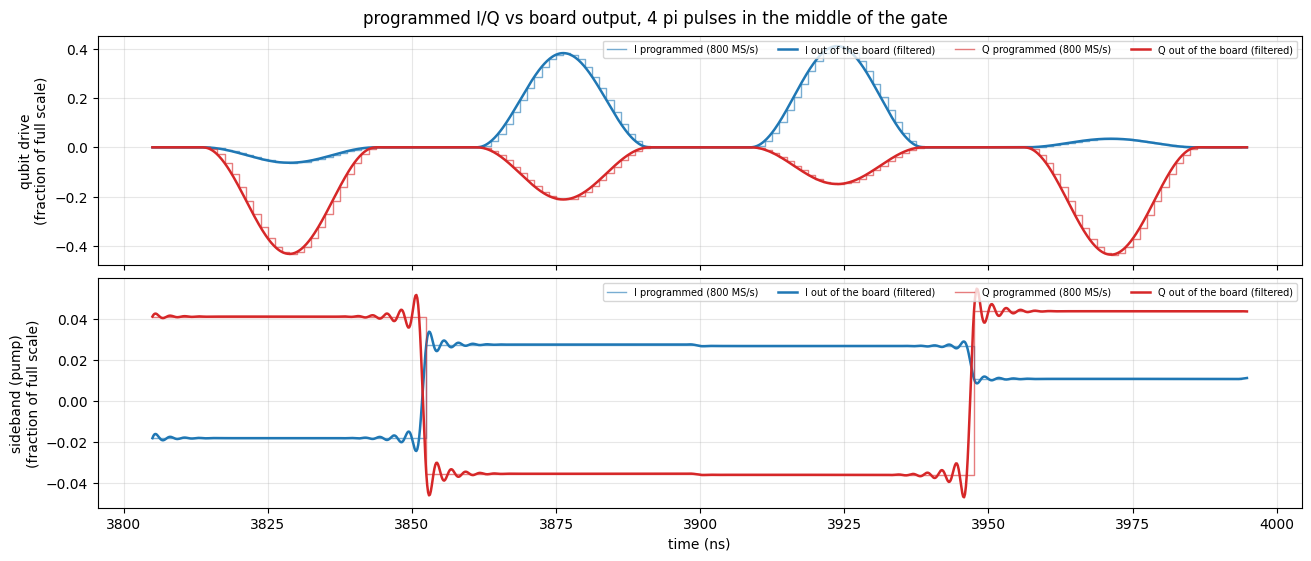

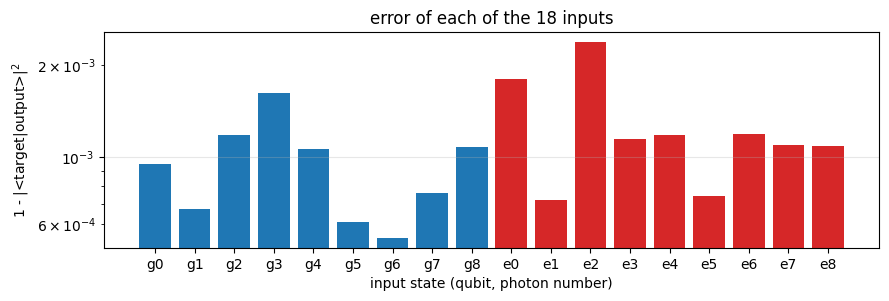

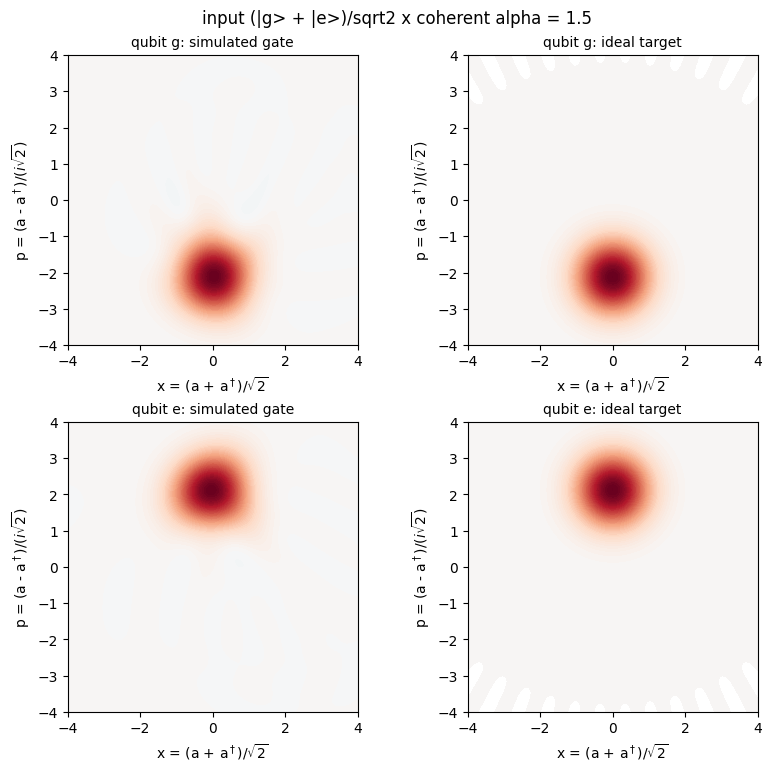

rotation of the coherent state: g branch -89.056 deg, e branch +90.938 deg, relative 179.994 deg (target -90, +90, 180)
full sequence (pulse, qubit phase, pump phase) for programming: runs/sequence_5.csv; int16 I/Q words: runs/words_5.npz


In [13]:
result = final[5]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.1f} ns, {result['time_us']:.2f} us")
print(f"How it was found: {job['found_start']} start in {job['found_in']} (F = {job['found_fidelity']:.5f}), then polished "
      f"with {result['evaluations']} more evaluations -> F = {result['fidelity']:.6f}")
print(f"Gate fidelity: model {result['at_192_levels']['fidelity']:.6f}, board waveform {result['hardware_check']['fidelity']:.6f} "
      f"(cutoff {result['hardware_check']['levels']} levels); worst single input {result['at_192_levels']['worst_input_fidelity']:.5f}")
print(f"After the gate: qubit Rz({result['qubit_frame_Rz']:.6f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)")
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=result["cells"] // 2, n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle of the gate")

# per-input fidelity
out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(18), 1 - abs(overlaps) ** 2, color=["C0"] * 9 + ["C3"] * 9)
ax.set_xticks(range(18), [f"g{n}" for n in range(9)] + [f"e{n}" for n in range(9)])
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 18 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# what the gate does
levels = tr.space.levels
if job["gate"] == "squeeze":
    vac = np.zeros(levels); vac[0] = 1
    sim, ideal = cp.wigner_panels(tr, x, vac, "input (|g> + |e>)/sqrt2 x vacuum: cavity state of each qubit branch")
    for branch, s, i in zip("ge", sim, ideal):
        db, angle = cp.squeezing_db(s); db_i, angle_i = cp.squeezing_db(i)
        print(f"qubit {branch}: squeezing {db:.3f} dB along {angle:+.2f} deg   (target {db_i:.3f} dB along {angle_i:+.2f} deg)")
else:
    alpha = 1.5
    sim, ideal = cp.wigner_panels(tr, x, cp.coherent(levels, alpha), f"input (|g> + |e>)/sqrt2 x coherent alpha = {alpha}")
    a = np.diag(np.sqrt(np.arange(1, levels)), 1)
    angles = [np.degrees(np.angle(np.vdot(s, a @ s))) for s in sim]
    print(f"rotation of the coherent state: g branch {angles[0]:+.3f} deg, e branch {angles[1]:+.3f} deg, "
          f"relative {((angles[1] - angles[0]) % 360):.3f} deg (target -90, +90, 180)")

table = pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1),
                          qubit_phase_deg=np.round(np.degrees(x[:result["cells"]]) % 360, 3),
                          pump_phase_deg=np.round(np.degrees(x[result["cells"]:]) % 360, 3)))
table.to_csv(f"{RUNS}/sequence_{5}.csv", index=False)
print(f"full sequence (pulse, qubit phase, pump phase) for programming: {RUNS}/sequence_{5}.csv; "
      f"int16 I/Q words: {RUNS}/{result['words_file']}")

### Gate [6]: rotation (π relative), 600 ns swap, constant sideband phase, 12.81 µs, 99.93 %

How it was found and its fidelities are printed first. Figures: (1) the whole pulse sequence: qubit π pulses (top line of each row) and sideband cells (bottom line), coloured by phase, gaps visible; (2) the phase of every π pulse and the drive envelopes; (3) programmed I/Q against what the board outputs, 4 pulses from the middle; (4) the error of each of the 18 inputs (shown separately from the process score, which also counts relative phases); (5) Wigner functions of the cavity in each qubit branch, simulated against ideal, with the measured squeezing (dB, axis) or rotation angles.

rotation, 600 ns swap, qubit only, >= 99.0%: 256 pi pulses, gap 20.0 ns, 12.81 us
How it was found: random 1 start in round2.json (F = 0.99897), then polished with 15001 more evaluations -> F = 0.999306
Gate fidelity: model 0.999306, board waveform 0.999286 (cutoff 256 levels); worst single input 0.99938
After the gate: qubit Rz(-3.530305 rad)


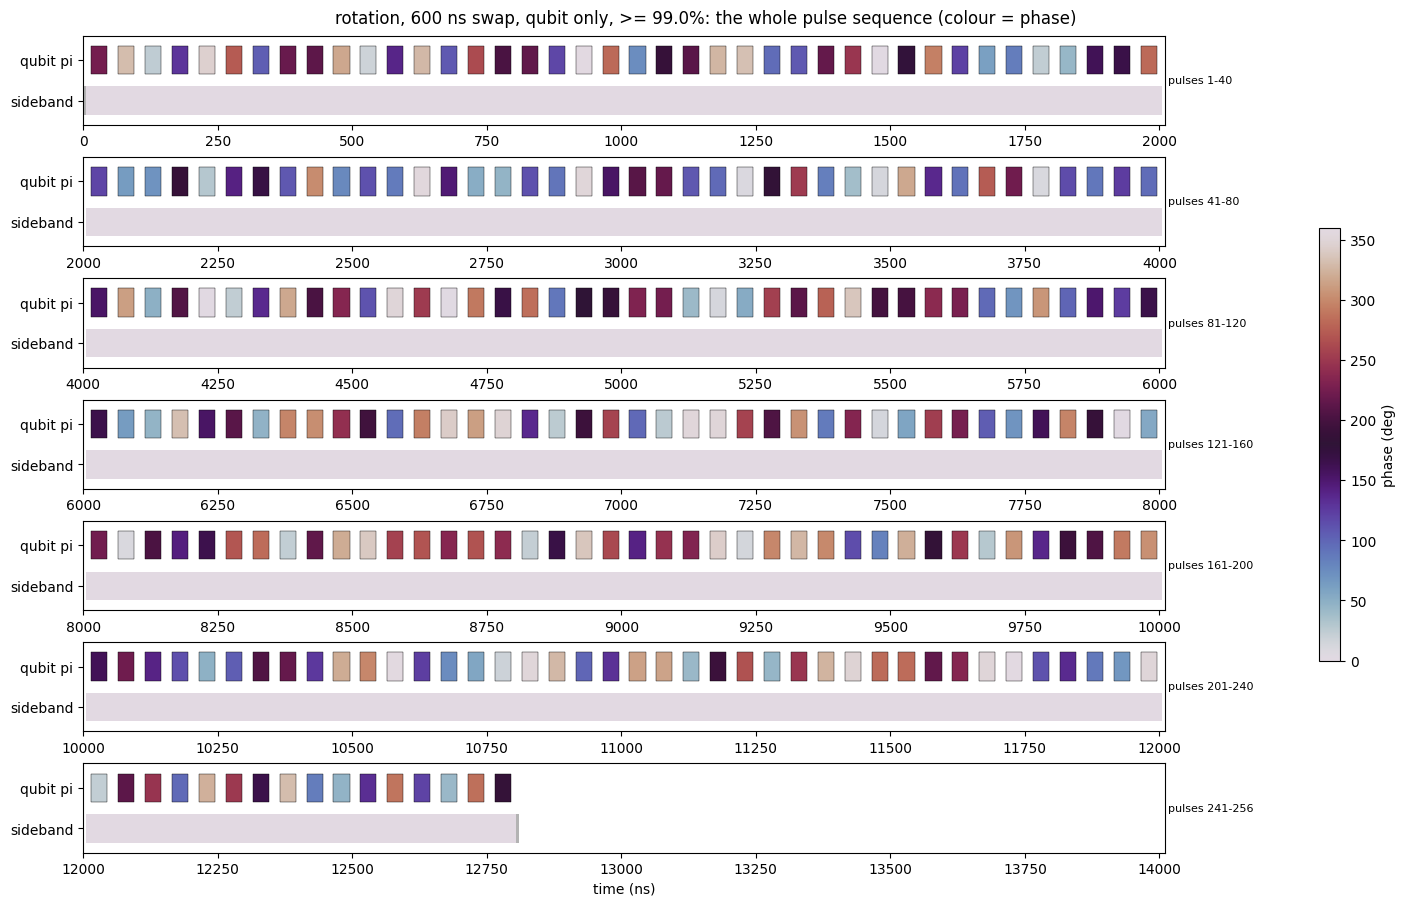

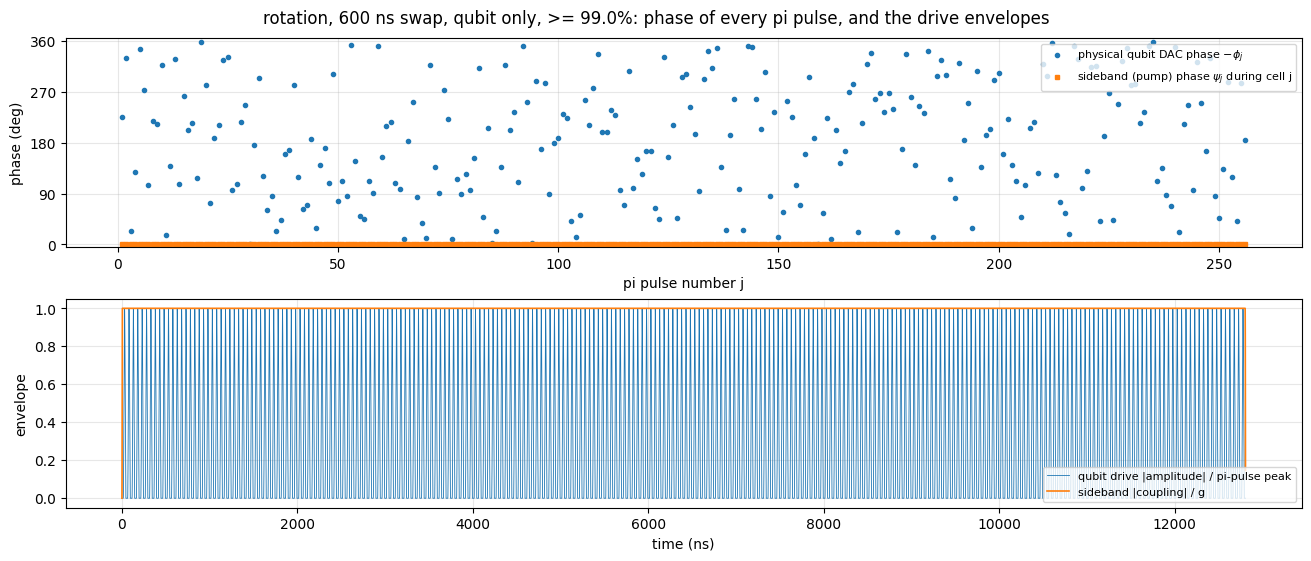

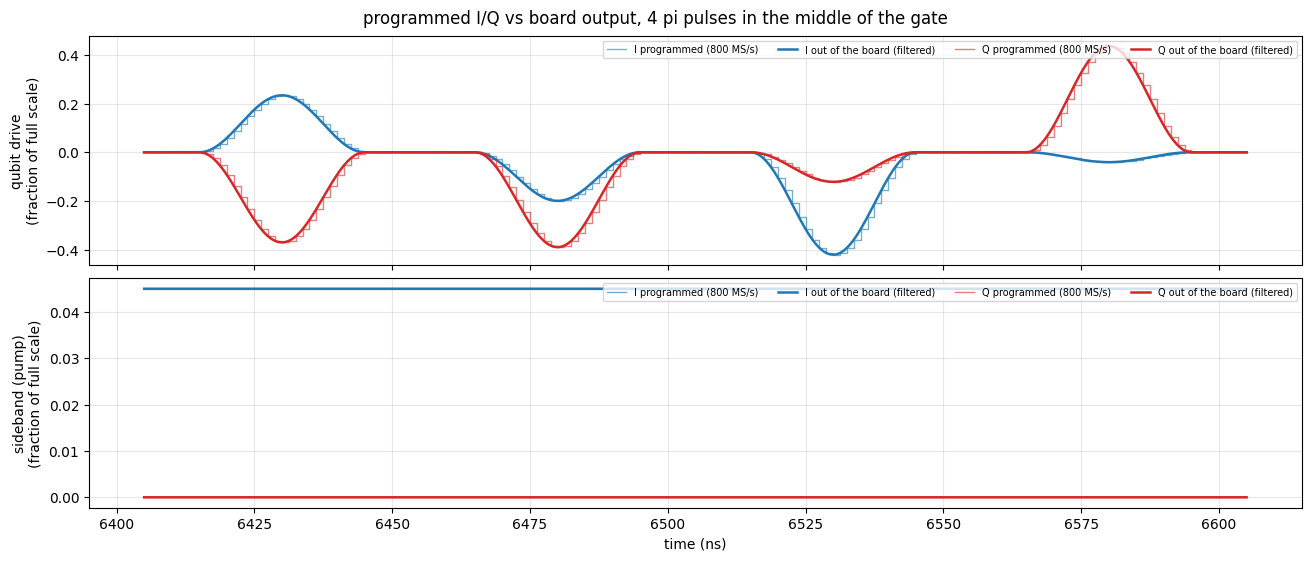

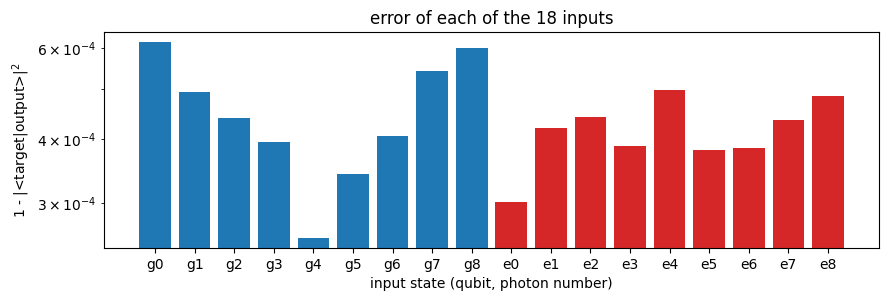

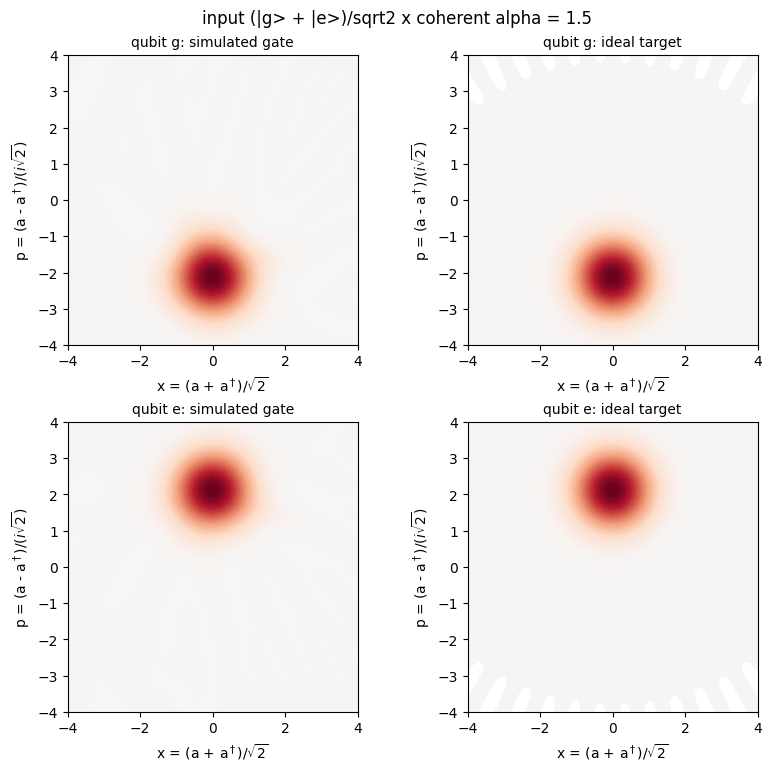

rotation of the coherent state: g branch -90.151 deg, e branch +90.195 deg, relative 180.346 deg (target -90, +90, 180)
full sequence (pulse, qubit phase, pump phase) for programming: runs/sequence_6.csv; int16 I/Q words: runs/words_6.npz


In [14]:
result = final[6]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.1f} ns, {result['time_us']:.2f} us")
print(f"How it was found: {job['found_start']} start in {job['found_in']} (F = {job['found_fidelity']:.5f}), then polished "
      f"with {result['evaluations']} more evaluations -> F = {result['fidelity']:.6f}")
print(f"Gate fidelity: model {result['at_192_levels']['fidelity']:.6f}, board waveform {result['hardware_check']['fidelity']:.6f} "
      f"(cutoff {result['hardware_check']['levels']} levels); worst single input {result['at_192_levels']['worst_input_fidelity']:.5f}")
print(f"After the gate: qubit Rz({result['qubit_frame_Rz']:.6f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)")
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=result["cells"] // 2, n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle of the gate")

# per-input fidelity
out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(18), 1 - abs(overlaps) ** 2, color=["C0"] * 9 + ["C3"] * 9)
ax.set_xticks(range(18), [f"g{n}" for n in range(9)] + [f"e{n}" for n in range(9)])
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 18 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# what the gate does
levels = tr.space.levels
if job["gate"] == "squeeze":
    vac = np.zeros(levels); vac[0] = 1
    sim, ideal = cp.wigner_panels(tr, x, vac, "input (|g> + |e>)/sqrt2 x vacuum: cavity state of each qubit branch")
    for branch, s, i in zip("ge", sim, ideal):
        db, angle = cp.squeezing_db(s); db_i, angle_i = cp.squeezing_db(i)
        print(f"qubit {branch}: squeezing {db:.3f} dB along {angle:+.2f} deg   (target {db_i:.3f} dB along {angle_i:+.2f} deg)")
else:
    alpha = 1.5
    sim, ideal = cp.wigner_panels(tr, x, cp.coherent(levels, alpha), f"input (|g> + |e>)/sqrt2 x coherent alpha = {alpha}")
    a = np.diag(np.sqrt(np.arange(1, levels)), 1)
    angles = [np.degrees(np.angle(np.vdot(s, a @ s))) for s in sim]
    print(f"rotation of the coherent state: g branch {angles[0]:+.3f} deg, e branch {angles[1]:+.3f} deg, "
          f"relative {((angles[1] - angles[0]) % 360):.3f} deg (target -90, +90, 180)")

table = pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1),
                          qubit_phase_deg=np.round(np.degrees(x[:result["cells"]]) % 360, 3),
                          pump_phase_deg=np.round(np.degrees(x[result["cells"]:]) % 360, 3)))
table.to_csv(f"{RUNS}/sequence_{6}.csv", index=False)
print(f"full sequence (pulse, qubit phase, pump phase) for programming: {RUNS}/sequence_{6}.csv; "
      f"int16 I/Q words: {RUNS}/{result['words_file']}")

### Gate [7]: rotation (π relative), 300 ns swap (2× sideband), 4.81 µs, 99.98 %

How it was found and its fidelities are printed first. Figures: (1) the whole pulse sequence: qubit π pulses (top line of each row) and sideband cells (bottom line), coloured by phase, gaps visible; (2) the phase of every π pulse and the drive envelopes; (3) programmed I/Q against what the board outputs, 4 pulses from the middle; (4) the error of each of the 18 inputs (shown separately from the process score, which also counts relative phases); (5) Wigner functions of the cavity in each qubit branch, simulated against ideal, with the measured squeezing (dB, axis) or rotation angles.

rotation, 300 ns swap, free, >= 99.9%: 160 pi pulses, gap 0.0 ns, 4.81 us
How it was found: the best no-gap sweep run (random start), continued start in round2.json (F = 0.99962), then polished with 15001 more evaluations -> F = 0.999825
Gate fidelity: model 0.999825, board waveform 0.999824 (cutoff 96 levels); worst single input 0.99987
After the gate: qubit Rz(-2.777244 rad)


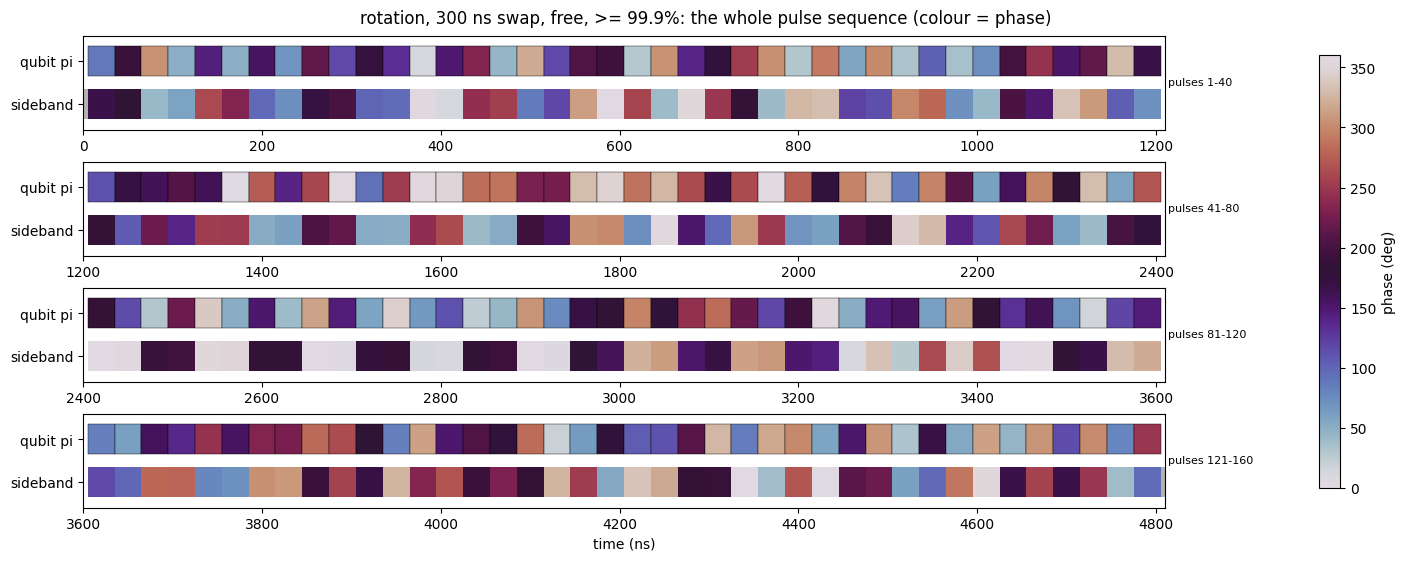

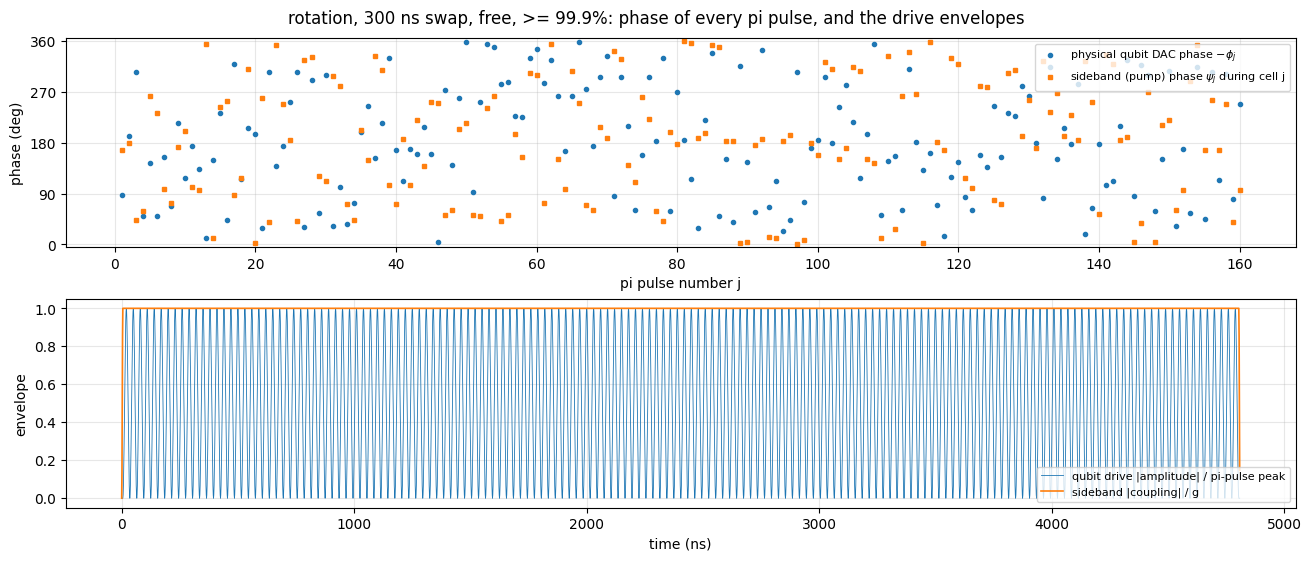

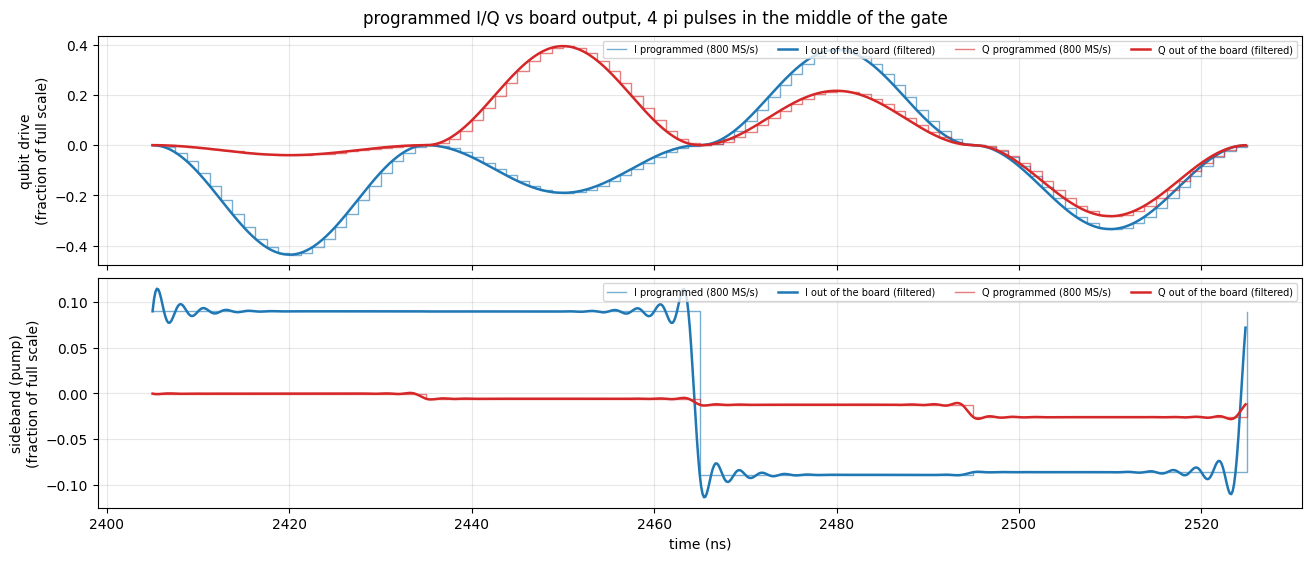

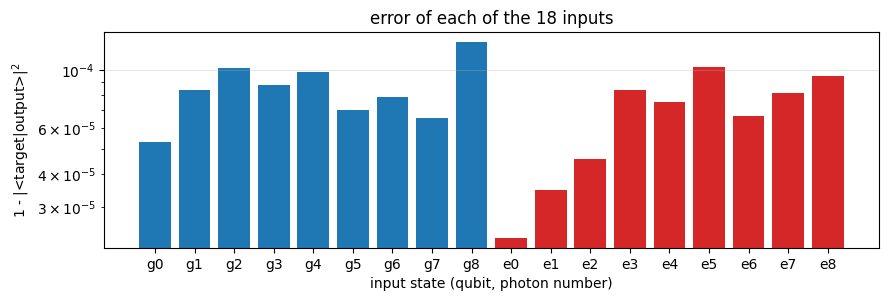

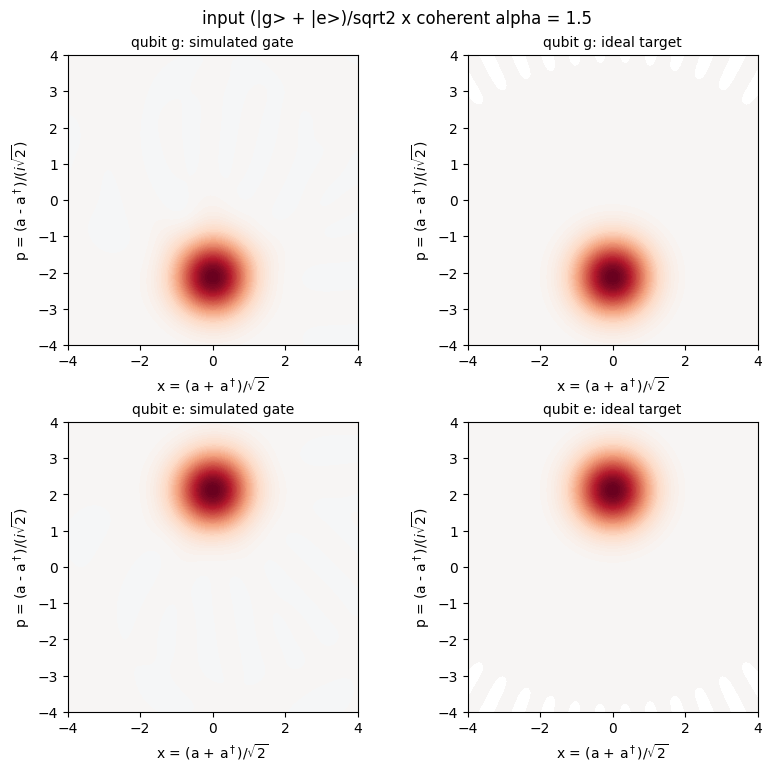

rotation of the coherent state: g branch -89.950 deg, e branch +89.982 deg, relative 179.932 deg (target -90, +90, 180)
full sequence (pulse, qubit phase, pump phase) for programming: runs/sequence_7.csv; int16 I/Q words: runs/words_7.npz


In [15]:
result = final[7]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.1f} ns, {result['time_us']:.2f} us")
print(f"How it was found: {job['found_start']} start in {job['found_in']} (F = {job['found_fidelity']:.5f}), then polished "
      f"with {result['evaluations']} more evaluations -> F = {result['fidelity']:.6f}")
print(f"Gate fidelity: model {result['at_192_levels']['fidelity']:.6f}, board waveform {result['hardware_check']['fidelity']:.6f} "
      f"(cutoff {result['hardware_check']['levels']} levels); worst single input {result['at_192_levels']['worst_input_fidelity']:.5f}")
print(f"After the gate: qubit Rz({result['qubit_frame_Rz']:.6f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)")
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=result["cells"] // 2, n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle of the gate")

# per-input fidelity
out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(18), 1 - abs(overlaps) ** 2, color=["C0"] * 9 + ["C3"] * 9)
ax.set_xticks(range(18), [f"g{n}" for n in range(9)] + [f"e{n}" for n in range(9)])
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 18 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# what the gate does
levels = tr.space.levels
if job["gate"] == "squeeze":
    vac = np.zeros(levels); vac[0] = 1
    sim, ideal = cp.wigner_panels(tr, x, vac, "input (|g> + |e>)/sqrt2 x vacuum: cavity state of each qubit branch")
    for branch, s, i in zip("ge", sim, ideal):
        db, angle = cp.squeezing_db(s); db_i, angle_i = cp.squeezing_db(i)
        print(f"qubit {branch}: squeezing {db:.3f} dB along {angle:+.2f} deg   (target {db_i:.3f} dB along {angle_i:+.2f} deg)")
else:
    alpha = 1.5
    sim, ideal = cp.wigner_panels(tr, x, cp.coherent(levels, alpha), f"input (|g> + |e>)/sqrt2 x coherent alpha = {alpha}")
    a = np.diag(np.sqrt(np.arange(1, levels)), 1)
    angles = [np.degrees(np.angle(np.vdot(s, a @ s))) for s in sim]
    print(f"rotation of the coherent state: g branch {angles[0]:+.3f} deg, e branch {angles[1]:+.3f} deg, "
          f"relative {((angles[1] - angles[0]) % 360):.3f} deg (target -90, +90, 180)")

table = pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1),
                          qubit_phase_deg=np.round(np.degrees(x[:result["cells"]]) % 360, 3),
                          pump_phase_deg=np.round(np.degrees(x[result["cells"]:]) % 360, 3)))
table.to_csv(f"{RUNS}/sequence_{7}.csv", index=False)
print(f"full sequence (pulse, qubit phase, pump phase) for programming: {RUNS}/sequence_{7}.csv; "
      f"int16 I/Q words: {RUNS}/{result['words_file']}")

## 9. What the verified calculations establish

In the effective, lossless JC model, the corrected SDK+RFDC replays give 8 dB
conditional squeezing in 7.61 us at 99.9304% and a pi-relative conditional number
rotation in 8.81 us at 99.9682%, using the 600 ns swap reference. The 300 ns swap
reference gives 4.81 us at 99.9549% and 99.9824%, respectively. These are coherent
process fidelities over all g/e times n=0..8 inputs with the listed final qubit
frame; they are not a worst-input guarantee or measured device fidelities.

For every accepted gate, the output and target cutoffs were enlarged until both
column changes were below $10^{-9}$, and an independent solver compared all
amplitudes. The surrogate/playback fidelity difference is below
$3.2\times10^{-5}$. The documented digital filter does not include an unmeasured
analog transfer function or driven-coupler physics.

Conditional-force commutators motivate the seeds and the plots in Section 3.
The finite-drive diagnostic and full unitary can also contain first-order motion,
other qubit axes and higher-order terms. No exact loop-area or Magnus-order
explanation is inferred from the phase list alone. Palindromic labels and
repeated motifs performed less well in the tested local fits; this is not a
proof that symmetry forbids these gates. Constant pump phase succeeded for
longer trains, including the 7.61 us squeeze at 99.4438% and 12.81 us rotation
at 99.9286%.

To use an effective-model sequence, play `runs/sequence_<n>.csv` or
`runs/words_<n>.npz` and apply its printed common qubit
$R_z(\zeta)=e^{-i\zeta\sigma_z/2}$. The exported **physical** qubit DAC phase is
minus its Hamiltonian-axis phase; the pump sign is unchanged. The supplied
lowering-operator I/Q convention has already been applied to these exports.

See the executed [coupler notebook](../../runs/audit/pre_story_notebooks/coupler_phase_transients.ipynb) for full
cosine-coupler calculations with programmed I/Q and 10 ns transitions. Its
representative CD(0.4) tests do not certify these long Gaussian trains. Loss,
nonideal qubit levels, unknown circuit parameters and an unmeasured analog
flux transfer remain outside the present device prediction.